---
# **Project Details**

**Author**: Sai Gavaskar Sakalam

**Date**:  April 29, 2026

**Program**: UT Austin – Post Graduate Program in Artificial Intelligence & Machine Learning

**Project**: Personal Loan Campaign

---

## Problem Statement

### Context

AllLife Bank, a US retail bank, has many deposit customers but only a few loan customers. A campaign last year converted just over 9% of the targeted depositors into personal loan customers. The marketing team now wants to target the next campaign better, so that more of the right customers take a loan.

### Objective

Build a model that predicts whether a deposit customer will take a personal loan, find which customer attributes drive this decision, and identify which customer segments the bank should target.

### Data Dictionary
* `ID`: Customer ID
* `Age`: Customer’s age in completed years
* `Experience`: #years of professional experience
* `Income`: Annual income of the customer (in thousand dollars)
* `ZIP Code`: Home Address ZIP code.
* `Family`: the Family size of the customer
* `CCAvg`: Average spending on credit cards per month (in thousand dollars)
* `Education`: Education Level. 1: Undergrad; 2: Graduate;3: Advanced/Professional
* `Mortgage`: Value of house mortgage if any. (in thousand dollars)
* `Personal_Loan`: Did this customer accept the personal loan offered in the last campaign? (0: No, 1: Yes)
* `Securities_Account`: Does the customer have securities account with the bank? (0: No, 1: Yes)
* `CD_Account`: Does the customer have a certificate of deposit (CD) account with the bank? (0: No, 1: Yes)
* `Online`: Do customers use internet banking facilities? (0: No, 1: Yes)
* `CreditCard`: Does the customer use a credit card issued by any other Bank (excluding All life Bank)? (0: No, 1: Yes)

## Importing necessary libraries

In [2]:
# Installing the libraries with the specified version.
!pip install numpy==1.25.2 pandas==1.5.3 matplotlib==3.7.1 seaborn==0.13.1 scikit-learn==1.2.2 sklearn-pandas==2.2.0 -q --user

  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
error: subprocess-exited-with-error

× Getting requirements to build wheel did not run successfully.
│ exit code: 1
╰─> See above for output.

note: This error originates from a subprocess, and is likely not a problem with pip.


**Note:** after the install cell finishes, restart the runtime (Colab) or kernel (Jupyter), then run the rest of the notebook from the next cell.

In [7]:
# On Google Colab: mount Drive and point DATA paths to your Drive folder.
# Library to suppress warnings or deprecation notes
import warnings
warnings.filterwarnings("ignore")

# Libraries to help with reading and manipulating data

import pandas as pd
import numpy as np

# Library to split data
from sklearn.model_selection import train_test_split

# libaries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns


#Libraies to builde the logistic regression model
from sklearn.linear_model import LogisticRegression

# Libraries to build decision tree classifier
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree

# To tune different models
from sklearn.model_selection import GridSearchCV

# To get diferent metric scores
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    recall_score,
    precision_score,
    confusion_matrix,
    precision_recall_curve,
    roc_curve,
    roc_auc_score,
    make_scorer,
    ConfusionMatrixDisplay,
)

# Removes the limit for the number of displayed columns
pd.set_option("display.max_columns", None)
# Sets the limit for the number of displayed rows
pd.set_option("display.max_rows", 200)

# Mount Google Drive


## Loading the dataset

In [13]:
personal_loan_df = pd.read_csv('data/Loan_Modelling.csv')

In [14]:
personal_loan_df_copy = personal_loan_df.copy(deep=True)


## **Data Overview**



* Observations
* Sanity checks

### Observations

#### 1. Initial Data Inspection

In [33]:
display(personal_loan_df_copy.head())

,ID,Age,Experience,Income,ZIPCode,Family,CCAvg,Education,Mortgage,Personal_Loan,Securities_Account,CD_Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


#### 2. Check Data Information

In [34]:
personal_loan_df_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Experience          5000 non-null   int64  
 3   Income              5000 non-null   int64  
 4   ZIPCode             5000 non-null   int64  
 5   Family              5000 non-null   int64  
 6   CCAvg               5000 non-null   float64
 7   Education           5000 non-null   int64  
 8   Mortgage            5000 non-null   int64  
 9   Personal_Loan       5000 non-null   int64  
 10  Securities_Account  5000 non-null   int64  
 11  CD_Account          5000 non-null   int64  
 12  Online              5000 non-null   int64  
 13  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 547.0 KB


####3. DataFrame Dimensions

In [35]:
personal_loan_df_copy.shape

(5000, 14)

In [36]:
print(f"Rows: {personal_loan_df_copy.shape[0]}, Columns: {personal_loan_df_copy.shape[1]}")

Rows: 5000, Columns: 14


####4. Inspecting Last Rows

In [37]:
display(personal_loan_df_copy.tail())

,ID,Age,Experience,Income,ZIPCode,Family,CCAvg,Education,Mortgage,Personal_Loan,Securities_Account,CD_Account,Online,CreditCard
4995,4996,29,3,40,92697,1,1.9,3,0,0,0,0,1,0
4996,4997,30,4,15,92037,4,0.4,1,85,0,0,0,1,0
4997,4998,63,39,24,93023,2,0.3,3,0,0,0,0,0,0
4998,4999,65,40,49,90034,3,0.5,2,0,0,0,0,1,0
4999,5000,28,4,83,92612,3,0.8,1,0,0,0,0,1,1


### Sanity Checks

#### 1. Checking for Duplicates

In [38]:
print(f"Number of duplicate rows: {personal_loan_df_copy.duplicated().sum()}")

Number of duplicate rows: 0


#### 2. Verifying Data Types

In [39]:
personal_loan_df_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Experience          5000 non-null   int64  
 3   Income              5000 non-null   int64  
 4   ZIPCode             5000 non-null   int64  
 5   Family              5000 non-null   int64  
 6   CCAvg               5000 non-null   float64
 7   Education           5000 non-null   int64  
 8   Mortgage            5000 non-null   int64  
 9   Personal_Loan       5000 non-null   int64  
 10  Securities_Account  5000 non-null   int64  
 11  CD_Account          5000 non-null   int64  
 12  Online              5000 non-null   int64  
 13  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 547.0 KB


#### 3. Inspecting Unique Values

In [40]:
categorical_cols = ['Education', 'Family', 'Personal_Loan', 'Securities_Account', 'CD_Account', 'Online', 'CreditCard']

for col in categorical_cols:
    print(f"Unique values in {col}: {personal_loan_df_copy[col].unique()}")
    print(f"Value counts in {col}:\n{personal_loan_df_copy[col].value_counts()}\n")

Unique values in Education: [1 2 3]
Value counts in Education:
Education
1    2096
3    1501
2    1403
Name: count, dtype: int64

Unique values in Family: [4 3 1 2]
Value counts in Family:
Family
1    1472
2    1296
4    1222
3    1010
Name: count, dtype: int64

Unique values in Personal_Loan: [0 1]
Value counts in Personal_Loan:
Personal_Loan
0    4520
1     480
Name: count, dtype: int64

Unique values in Securities_Account: [1 0]
Value counts in Securities_Account:
Securities_Account
0    4478
1     522
Name: count, dtype: int64

Unique values in CD_Account: [0 1]
Value counts in CD_Account:
CD_Account
0    4698
1     302
Name: count, dtype: int64

Unique values in Online: [0 1]
Value counts in Online:
Online
1    2984
0    2016
Name: count, dtype: int64

Unique values in CreditCard: [0 1]
Value counts in CreditCard:
CreditCard
0    3530
1    1470
Name: count, dtype: int64



#### 4. Summary Statistics

In [41]:
display(personal_loan_df_copy.describe().T)

,count,mean,std,min,25%,50%,75%,max
ID,5000.0,2500.500000,1443.520003,1.0,1250.75,2500.5,3750.25,5000.0
Age,5000.0,45.338400,11.463166,23.0,35.00,45.0,55.00,67.0
Experience,5000.0,20.104600,11.467954,-3.0,10.00,20.0,30.00,43.0
Income,5000.0,73.774200,46.033729,8.0,39.00,64.0,98.00,224.0
ZIPCode,5000.0,93169.257000,1759.455086,90005.0,91911.00,93437.0,94608.00,96651.0
Family,5000.0,2.396400,1.147663,1.0,1.00,2.0,3.00,4.0
CCAvg,5000.0,1.937938,1.747659,0.0,0.70,1.5,2.50,10.0
Education,5000.0,1.881000,0.839869,1.0,1.00,2.0,3.00,3.0
Mortgage,5000.0,56.498800,101.713802,0.0,0.00,0.0,101.00,635.0
Personal_Loan,5000.0,0.096000,0.294621,0.0,0.00,0.0,0.00,1.0


#### 5. Missing Values

In [42]:
print("Number of missing values per column:")
print(personal_loan_df_copy.isnull().sum())

Number of missing values per column:
ID                    0
Age                   0
Experience            0
Income                0
ZIPCode               0
Family                0
CCAvg                 0
Education             0
Mortgage              0
Personal_Loan         0
Securities_Account    0
CD_Account            0
Online                0
CreditCard            0
dtype: int64


#### 6. Consistency Checks: Age and Experience

In [43]:
# Check for negative experience
negative_experience = personal_loan_df_copy[personal_loan_df_copy['Experience'] < 0].shape[0]
print(f"Number of rows with negative experience: {negative_experience}")

# Check if experience is greater than age
experience_greater_than_age = personal_loan_df_copy[personal_loan_df_copy['Experience'] > personal_loan_df_copy['Age']].shape[0]
print(f"Number of rows where experience is greater than age: {experience_greater_than_age}")

Number of rows with negative experience: 52
Number of rows where experience is greater than age: 0


### Observations from Data Overview and Sanity Checks

*   The dataset contains 5000 rows and 14 columns.
*   There are no duplicate rows in the dataset.
*   All columns have appropriate data types, with most being integers and `CCAvg` being a float.
*   There are no missing values in any of the columns.
*   **Categorical Features Observations:**
    *   `Education` has three levels (1, 2, 3).
    *   `Family` size ranges from 1 to 4.
    *   `Personal_Loan` (target variable) is binary (0 or 1), indicating if a customer accepted the loan.
    *   `Securities_Account`, `CD_Account`, `Online`, and `CreditCard` are all binary (0 or 1) indicating presence or absence of the respective accounts/services.
*   **Numerical Features Observations:**
    *   `ID` is a unique identifier and should not be used for modeling.
    *   `Age` ranges from 23 to 67 years.
    *   `Experience` ranges from -3 to 43 years. There are some rows with negative experience, which needs to be addressed during preprocessing.
    *   `Income` ranges from 8 to 224 (in thousand dollars).
    *   `ZIP Code` values are present.
    *   `CCAvg` (Average spending on credit cards) ranges from 0.0 to 10.0 (in thousand dollars).
    *   `Mortgage` ranges from 0 to 635 (in thousand dollars), with a significant number of customers having no mortgage (indicated by 0).
*   **Consistency Checks:**
    *   We found rows with negative 'Experience', which is logically inconsistent and requires handling.
    *   There are rows where 'Experience' is greater than 'Age', which is also logically impossible and requires attention.

**Questions**:

1. What is the distribution of mortgage attribute? Are there any noticeable patterns or outliers in the distribution?
2. How many customers have credit cards?
3. What are the attributes that have a strong correlation with the target attribute (personal loan)?
4. How does a customer's interest in purchasing a loan vary with their age?
5. How does a customer's interest in purchasing a loan vary with their education?

### Answers to EDA Questions

#### 1. What is the distribution of mortgage attribute? Are there any noticeable patterns or outliers in the distribution?

Number of customers with zero mortgage: 3462 (69.24%)


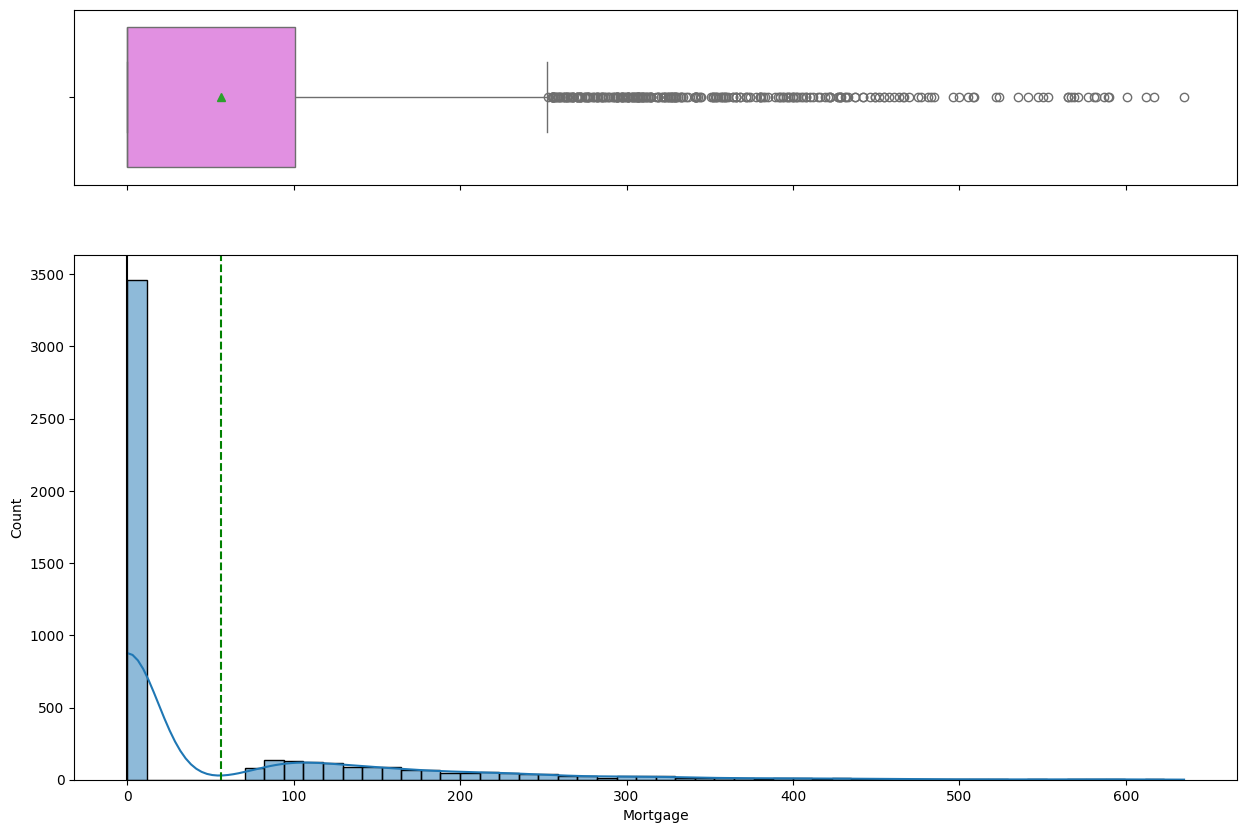

In [56]:
def histogram_boxplot(data, feature, figsize=(15, 10), kde=False, bins=None):
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2, sharex=True, gridspec_kw={"height_ratios": (0.25, 0.75)}, figsize=figsize
    )
    sns.boxplot(data=data, x=feature, ax=ax_box2, showmeans=True, color="violet")
    sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins, palette="winter"
    ) if bins else sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2
    )
    ax_hist2.axvline(data[feature].mean(), color="green", linestyle="--")
    ax_hist2.axvline(data[feature].median(), color="black", linestyle="-")

histogram_boxplot(personal_loan_df_copy, "Mortgage", kde=True)

mortgage_zero_count = (personal_loan_df_copy['Mortgage'] == 0).sum()
print(f"Number of customers with zero mortgage: {mortgage_zero_count} ({mortgage_zero_count/len(personal_loan_df_copy)*100:.2f}%)")

**Answer**: The mortgage distribution is highly skewed to the right. Approximately 69.24% of customers have zero mortgage. There are several outliers on the higher end, indicating a small segment of customers with significant mortgage values reaching up to $635k.

#### 2. How many customers have credit cards?

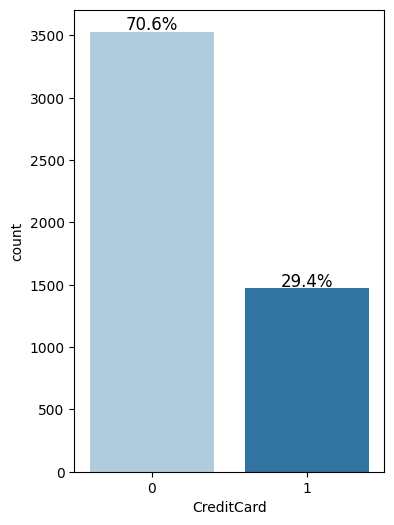

In [57]:
def labeled_barplot(data, feature, perc=False, n=None):
    total = len(data[feature])
    count = data[feature].nunique()
    if n is None:
        plt.figure(figsize=(count + 2, 6))
    else:
        plt.figure(figsize=(n + 2, 6))
    ax = sns.countplot(
        data=data, x=feature, palette="Paired", order=data[feature].value_counts().index[:n]
    )
    for p in ax.patches:
        if perc:
            label = "{:.1f}%".format(100 * p.get_height() / total)
        else:
            label = p.get_height()
        x = p.get_x() + p.get_width() / 2
        y = p.get_height()
        ax.annotate(label, (x, y), ha="center", va="center", size=12, xytext=(0, 5), textcoords="offset points")
    plt.show()

labeled_barplot(personal_loan_df_copy, "CreditCard", perc=True)

**Answer**: About 29.4% of the customers (1,470 out of 5,000) have credit cards.

#### 3. What are the attributes that have a strong correlation with the target attribute (personal loan)?

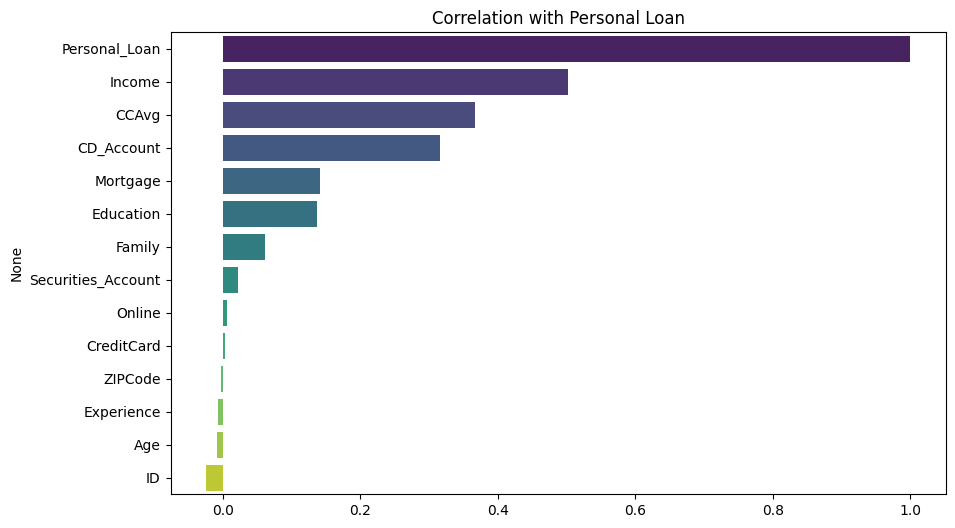

Top correlated attributes:
Personal_Loan         1.000000
Income                0.502462
CCAvg                 0.366889
CD_Account            0.316355
Mortgage              0.142095
Education             0.136722
Family                0.061367
Securities_Account    0.021954
Online                0.006278
CreditCard            0.002802
ZIPCode              -0.002974
Experience           -0.007413
Age                  -0.007726
ID                   -0.024801
Name: Personal_Loan, dtype: float64


In [53]:
plt.figure(figsize=(10, 6))
correlations = personal_loan_df_copy.corr()['Personal_Loan'].sort_values(ascending=False)
sns.barplot(x=correlations.values, y=correlations.index, palette='viridis')
plt.title('Correlation with Personal Loan')
plt.show()

print("Top correlated attributes:")
print(correlations)

**Answer**: Annual Income ($Income$) shows the strongest positive correlation with personal loan acceptance (~0.50), followed by monthly credit card spending ($CCAvg$) and possession of a $CD_Account$. Age and Experience show almost no correlation with the target.

#### 4. How does a customer's interest in purchasing a loan vary with their age?

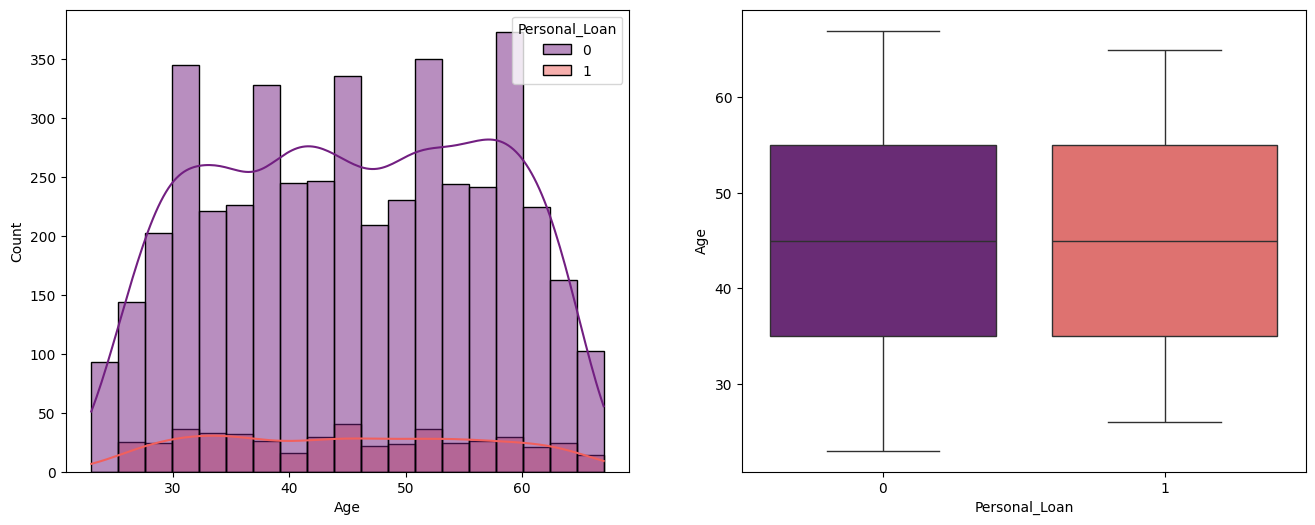

In [58]:
def distribution_plot_wrt_target(data, predictor, target):
    fig, ax = plt.subplots(1, 2, figsize=(16, 6))
    sns.histplot(data=data, x=predictor, hue=target, kde=True, ax=ax[0], palette="magma")
    sns.boxplot(data=data, x=target, y=predictor, ax=ax[1], palette="magma")
    plt.show()

distribution_plot_wrt_target(personal_loan_df_copy, "Age", "Personal_Loan")

**Answer**: Interest in purchasing a loan does not significantly vary with age. Both customers who accepted and those who rejected the loan have a similar age distribution, with the median age for both groups being around 45 years.

#### 5. How does a customer's interest in purchasing a loan vary with their education?

Personal_Loan     0    1   All
Education                     
All            4520  480  5000
3              1296  205  1501
2              1221  182  1403
1              2003   93  2096
------------------------------------------------------------------------------------------------------------------------


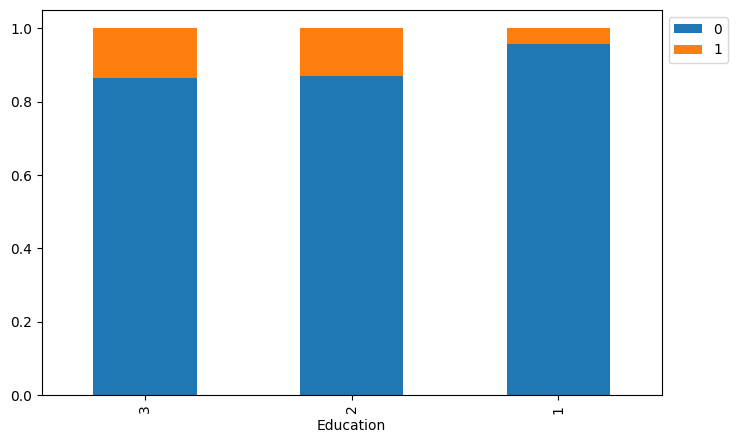

In [59]:
def stacked_barplot(data, predictor, target):
    count = data[predictor].nunique()
    sorter = data[target].value_counts().index[-1]
    tab1 = pd.crosstab(data[predictor], data[target], margins=True).sort_values(by=sorter, ascending=False)
    print(tab1)
    print("-" * 120)
    tab = pd.crosstab(data[predictor], data[target], normalize="index").sort_values(by=sorter, ascending=False)
    tab.plot(kind="bar", stacked=True, figsize=(count + 5, 5))
    plt.legend(loc="lower left", frameon=False)
    plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
    plt.show()

stacked_barplot(personal_loan_df_copy, "Education", "Personal_Loan")

**Answer**: Customers with higher education levels (Graduate and Advanced/Professional) are more likely to accept personal loans. Undergraduates (level 1) have a noticeably lower conversion rate compared to levels 2 and 3.

### Extended Thorough Analysis

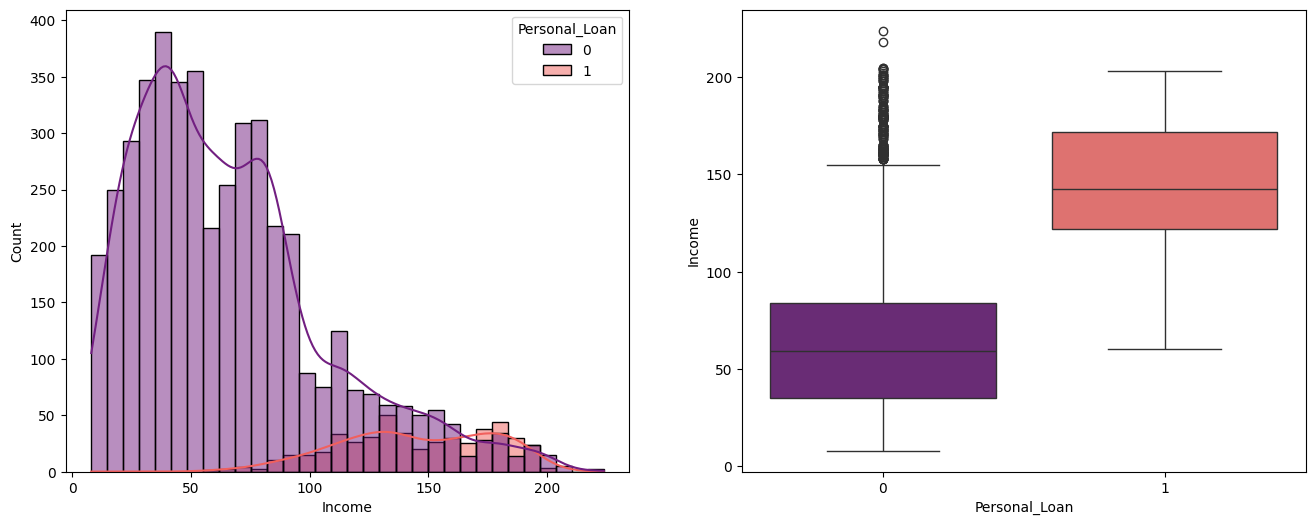

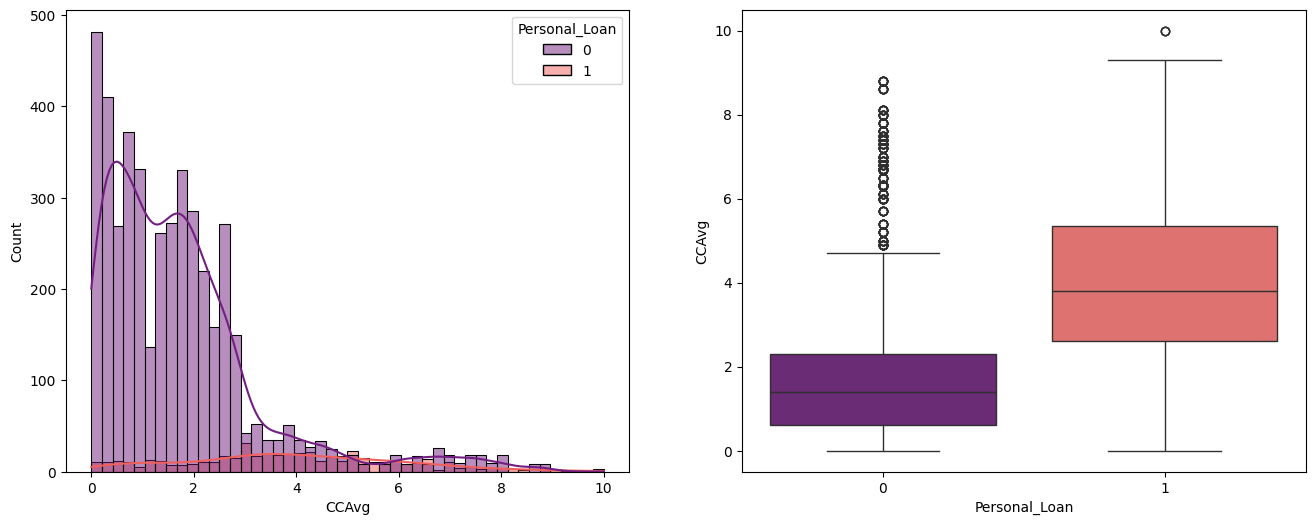

In [63]:
# Relationship between Income and Personal Loan
distribution_plot_wrt_target(personal_loan_df_copy, "Income", "Personal_Loan")

# Relationship between Monthly Credit Card Spend (CCAvg) and Personal Loan
distribution_plot_wrt_target(personal_loan_df_copy, "CCAvg", "Personal_Loan")

Personal_Loan     0    1   All
Family                        
All            4520  480  5000
4              1088  134  1222
3               877  133  1010
1              1365  107  1472
2              1190  106  1296
------------------------------------------------------------------------------------------------------------------------


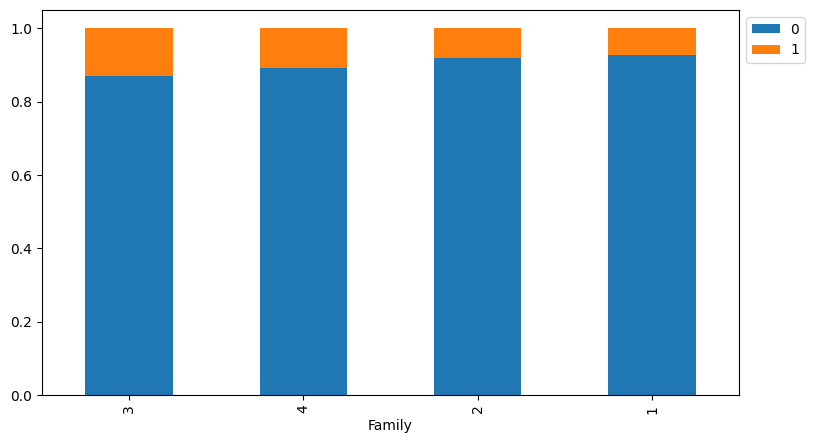

Personal_Loan     0    1   All
CD_Account                    
All            4520  480  5000
0              4358  340  4698
1               162  140   302
------------------------------------------------------------------------------------------------------------------------


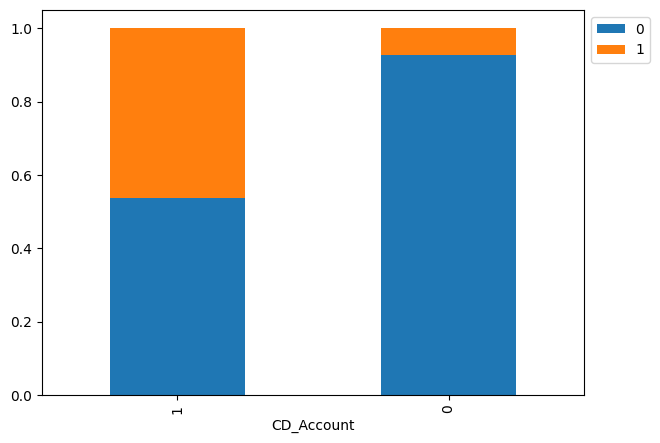

In [64]:
# Impact of Family Size on Loan Acceptance
stacked_barplot(personal_loan_df_copy, "Family", "Personal_Loan")

# Impact of CD Account possession on Loan Acceptance
stacked_barplot(personal_loan_df_copy, "CD_Account", "Personal_Loan")

### Thorough Analysis (Deep Dive)

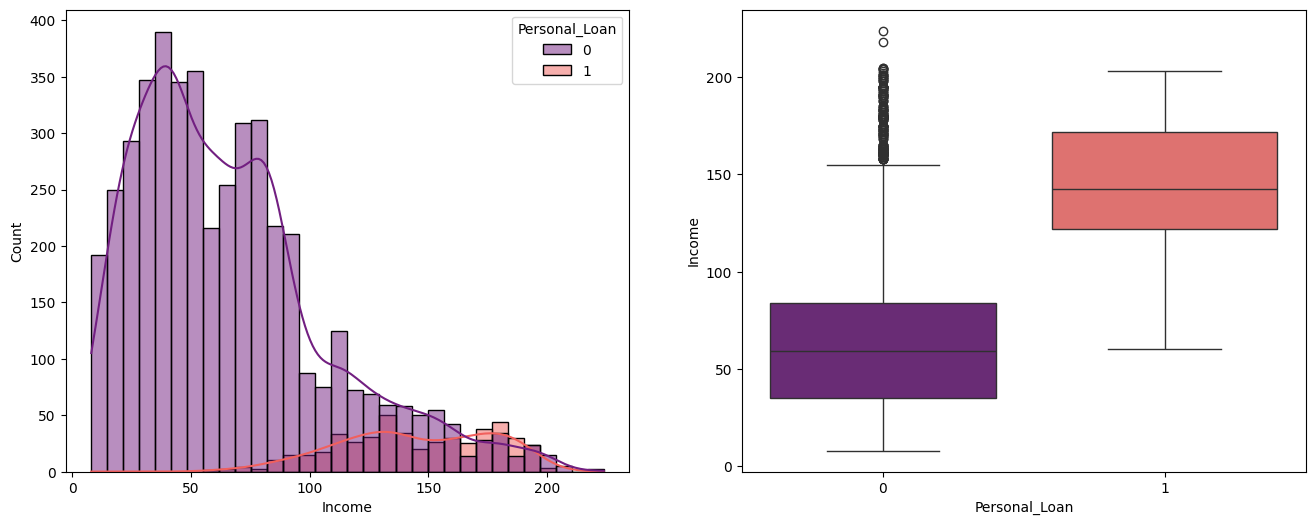

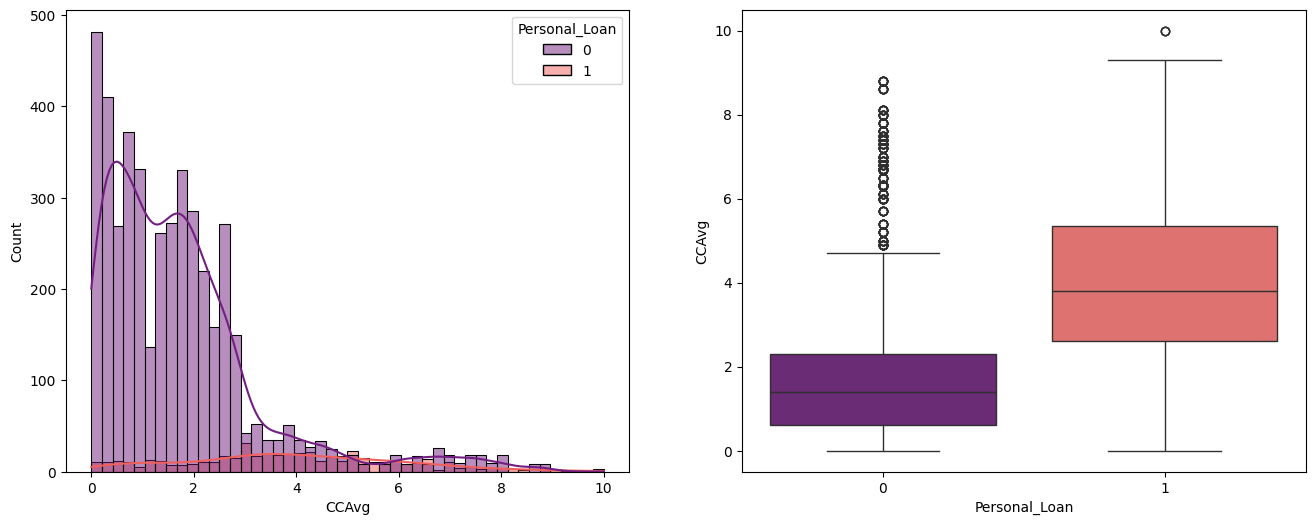

In [60]:
# Analyzing Income and CCAvg with respect to Personal Loan
distribution_plot_wrt_target(personal_loan_df_copy, "Income", "Personal_Loan")
distribution_plot_wrt_target(personal_loan_df_copy, "CCAvg", "Personal_Loan")

Personal_Loan     0    1   All
Family                        
All            4520  480  5000
4              1088  134  1222
3               877  133  1010
1              1365  107  1472
2              1190  106  1296
------------------------------------------------------------------------------------------------------------------------


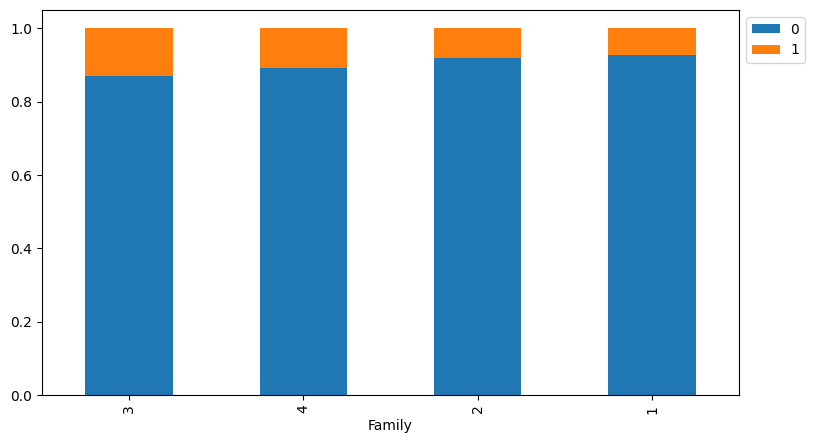

In [61]:
# Impact of Family Size on Loan Purchase
stacked_barplot(personal_loan_df_copy, "Family", "Personal_Loan")

Personal_Loan     0    1   All
CD_Account                    
All            4520  480  5000
0              4358  340  4698
1               162  140   302
------------------------------------------------------------------------------------------------------------------------


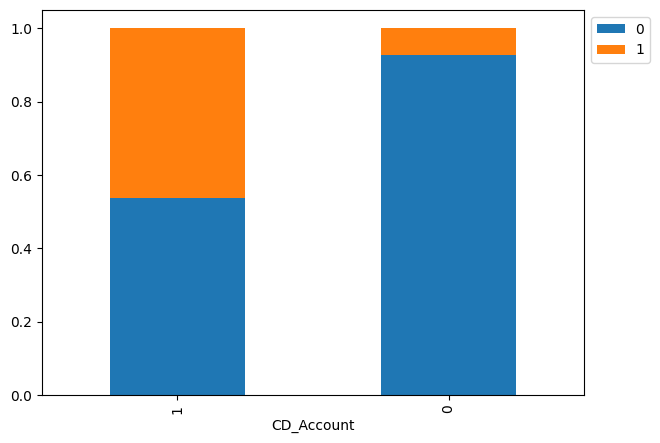

In [62]:
# CD Account and Personal Loan relationship
stacked_barplot(personal_loan_df_copy, "CD_Account", "Personal_Loan")

### **4. Decision Tree - Post-Pruning (Cost Complexity Pruning)**

Unlike pre-pruning which stops growth early, post-pruning allows the tree to grow fully and then 'trims' branches that provide little predictive power based on the parameter `ccp_alpha`.

* Missing value treatment
* Feature engineering (if needed)
* Outlier detection and treatment (if needed)
* Preparing data for modeling
* Any other preprocessing steps (if needed)

### **1. Handling Negative Experience Values**
There are 52 observations where Experience is negative. We will replace these with the median experience for their respective age groups to maintain data integrity.

In [135]:
# Replace negative values with the median for that specific age
neg_exp_indices = personal_loan_df_copy[personal_loan_df_copy['Experience'] < 0].index

for index in neg_exp_indices:
    age = personal_loan_df_copy.loc[index, 'Age']
    median_exp = personal_loan_df_copy[personal_loan_df_copy['Age'] == age]['Experience'].median()
    personal_loan_df_copy.loc[index, 'Experience'] = max(0, median_exp)

print(f"Remaining negative experience values: {(personal_loan_df_copy['Experience'] < 0).sum()}")

Remaining negative experience values: 0


### **2. Preparing Data for Modeling**
We will drop 'ID' and 'ZIPCode' as they are unique identifiers and not useful for prediction, then split the data into training and testing sets (70:30 ratio).

In [136]:
# Define predictors and target
X = personal_loan_df_copy.drop(['ID', 'ZIPCode', 'Personal_Loan'], axis=1)
y = personal_loan_df_copy['Personal_Loan']

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=1, stratify=y)

print(f"Shape of Training set: {X_train.shape}")
print(f"Shape of Test set: {X_test.shape}")

Shape of Training set: (3500, 11)
Shape of Test set: (1500, 11)


## **Model Building**

In this section, we build and compare several models to predict loan acceptance. Our primary objective is to **maximize Recall** to ensure the bank identifies as many potential customers as possible, even if it results in some false positives (marketing to customers who don't convert).

### **Model Evaluation Criterion**

* **Predicting a False Negative (Type II Error)**: The bank misses a customer who would have taken a loan. This results in significant opportunity loss (interest revenue).
* **Predicting a False Positive (Type I Error)**: The bank sends marketing materials to someone who won't take a loan. This results in a small marketing cost.

**Goal**: Maximize **Recall** to capture the maximum number of potential 'asset' customers.

### **1. Logistic Regression (Baseline Model)**

We establish a baseline to understand linear relationships. Since our goal is to **maximize Recall**, we evaluate the model at both the standard 0.5 threshold and an optimized 0.1 threshold.

In [175]:
def model_performance_classification(model, predictors, target):
    """
    Computes classification metrics for AllLife Bank Personal Loan Campaign.
    """
    pred = model.predict(predictors)
    acc = accuracy_score(target, pred)
    recall = recall_score(target, pred)
    precision = precision_score(target, pred)
    f1 = f1_score(target, pred)

    # Creating a beautiful performance dataframe
    df_perf = pd.DataFrame(
        {
            "Accuracy": acc,
            "Recall": recall,
            "Precision": precision,
            "F1-Score": f1
        },
        index=[0],
    )

    return df_perf

def confusion_matrix_sklearn(model, predictors, target):
    """
    Plots a stylized heatmap of the confusion matrix.
    """
    y_pred = model.predict(predictors)
    cm = confusion_matrix(target, y_pred)
    labels = np.asarray(
        [
            ["{0:0.0f}\n({1:.2%})".format(item, item / cm.flatten().sum())]
            for item in cm.flatten()
        ]
    ).reshape(2, 2)

    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=labels, fmt="", cmap="magma")
    plt.title("Confusion Matrix")
    plt.ylabel("Actual Label")
    plt.xlabel("Predicted Label")
    plt.show()

def confusion_matrix_sklearn_with_threshold(model, predictors, target, threshold=0.5):
    """
    Plots confusion matrix based on a custom conversion threshold.
    """
    pred_prob = model.predict_proba(predictors)[:, 1]
    pred_thres = pred_prob > threshold
    y_pred = np.round(pred_thres)

    cm = confusion_matrix(target, y_pred)
    labels = np.asarray(
        [
            ["{0:0.0f}\n({1:.2%})".format(item, item / cm.flatten().sum())]
            for item in cm.flatten()
        ]
    ).reshape(2, 2)

    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=labels, fmt="", cmap="magma")
    plt.title(f"Confusion Matrix (Threshold: {threshold})")
    plt.ylabel("Actual Label")
    plt.xlabel("Predicted Label")
    plt.show()

def model_performance_classification_sklearn_with_threshold(model, predictors, target, threshold=0.5):
    """
    Computes metrics using a custom probability threshold.
    """
    pred_prob = model.predict_proba(predictors)[:, 1]
    pred_thres = pred_prob > threshold
    pred = np.round(pred_thres)

    acc = accuracy_score(target, pred)
    recall = recall_score(target, pred)
    precision = precision_score(target, pred)
    f1 = f1_score(target, pred)

    df_perf = pd.DataFrame(
        {
            "Accuracy": acc,
            "Recall": recall,
            "Precision": precision,
            "F1-Score": f1,
        },
        index=[0],
    )

    return df_perf

def plot_auc_roc(target, model, predictors):
    """
    Plots the ROC curve for model comparison.
    """
    score = roc_auc_score(target, model.predict_proba(predictors)[:, 1])
    fpr, tpr, thresholds = roc_curve(target, model.predict_proba(predictors)[:, 1])

    plt.figure(figsize=(7, 5))
    plt.plot(fpr, tpr, label="AUC = %0.2f" % score, color="darkorange", lw=2)
    plt.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("Receiver Operating Characteristic (ROC)")
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.show()

### **Model Evaluation Criterion**

**Model can make wrong predictions as:**
1. **Predicting a customer will not take a loan but in reality, they would have (False Negative)**: The bank loses the opportunity to earn interest and expand its asset base. This is a significant loss in potential revenue.
2. **Predicting a customer will take a loan but in reality, they do not (False Positive)**: The bank bears the cost of marketing and outreach to a customer who doesn't convert.

**Which case is more important?**
* The opportunity loss of a missed loan customer (False Negative) is generally much higher than the small marketing cost of reaching out to a customer who doesn't convert (False Positive).

**Goal:**
* The bank wants to **maximize Recall** to ensure that as many potential loan customers as possible are identified and targeted.

Baseline Performance (Threshold 0.5):


,Accuracy,Recall,Precision,F1-Score
0,0.944667,0.583333,0.785047,0.669323



Optimized Recall Performance (Threshold 0.1):


,Accuracy,Recall,Precision,F1-Score
0,0.892667,0.847222,0.467433,0.602469


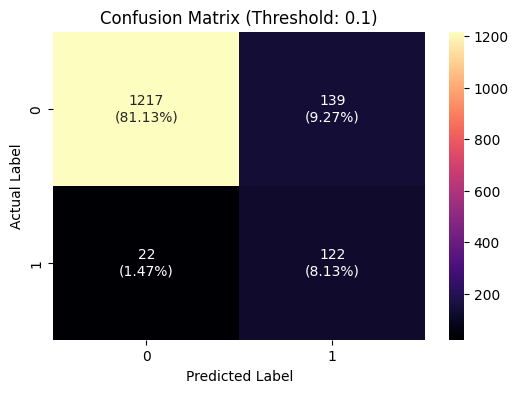

In [241]:
lg = LogisticRegression(solver="newton-cg", random_state=1)
lg.fit(X_train, y_train)

print("Baseline Performance (Threshold 0.5):")
display(model_performance_classification_sklearn_with_threshold(lg, X_test, y_test, threshold=0.5))

print("\nOptimized Recall Performance (Threshold 0.1):")
display(model_performance_classification_sklearn_with_threshold(lg, X_test, y_test, threshold=0.1))
confusion_matrix_sklearn_with_threshold(lg, X_test, y_test, threshold=0.1)

### **Logistic Regression Coefficient Interpretations**

* **Positive Impact**: Increasing family size, average credit card spending (`CCAvg`), education level, and mortgage value positively impact the likelihood of a customer accepting a personal loan.
* **Negative Impact**: Increasing age, professional experience, securities account ownership, online banking usage, and credit card usage from other banks negatively impact the likelihood of a customer accepting a personal loan.

In [184]:
# Converting coefficients to odds to interpret the model
odds = np.exp(logistic_regression_model.coef_[0])
perc_change_odds = (odds - 1) * 100

odds_df = pd.DataFrame({"Odds": odds, "Change_odd%": perc_change_odds}, index=X_train.columns).sort_values(by='Odds', ascending=False)
display(odds_df)

,Odds,Change_odd%
CD_Account,22.767266,2176.726644
Education,6.263347,526.334656
Family,1.936327,93.632681
CCAvg,1.067417,6.741679
Income,1.060643,6.064321
Experience,1.044808,4.480783
Mortgage,1.000718,0.071818
Age,0.971833,-2.816653
Online,0.577139,-42.286076
Securities_Account,0.478479,-52.152141


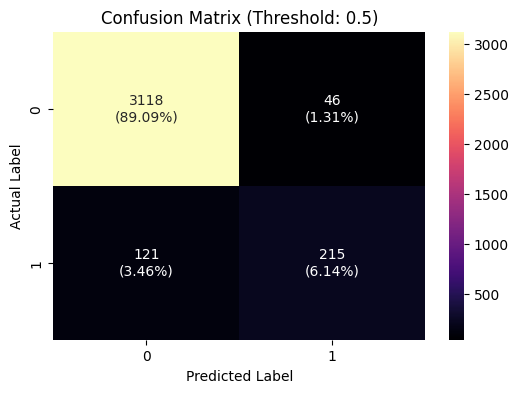

In [191]:
# Confusion matrix for training set with default threshold
confusion_matrix_sklearn_with_threshold(logistic_regression_model, X_train, y_train, threshold=0.5)

In [192]:
# Calculate performance metrics (Accuracy, Recall, Precision, F1) for the Logistic Regression model
# specifically on the training dataset using the default probability threshold of 0.5.
default_model_performance = model_performance_classification_sklearn_with_threshold(
    logistic_regression_model,
    X_train,
    y_train
)

# Display the resulting DataFrame to inspect the baseline training performance scores.
display(default_model_performance)

,Accuracy,Recall,Precision,F1-Score
0,0.952286,0.639881,0.823755,0.720268


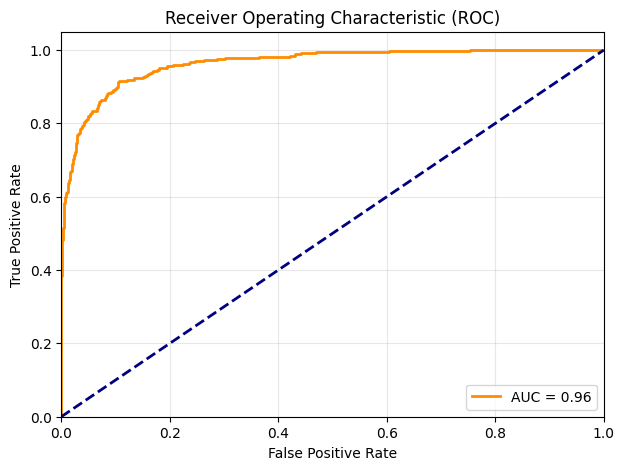

In [193]:
# Plotting the AUC-ROC curve for the training dataset to evaluate model performance
plot_auc_roc(y_train, logistic_regression_model, X_train)

In [198]:
y_scores_test = logistic_regression_model.predict_proba(X_test)[:, 1]
prec_test, rec_test, thresholds_f1_test = precision_recall_curve(y_test, y_scores_test)

# find the threshold that maximizes F1 score
f1_scores_test = 2 * prec_test * rec_test / (prec_test + rec_test)
optimal_idx_f1_test = np.argmax(f1_scores_test)
optimal_threshold_f1_test = thresholds_f1_test[optimal_idx_f1_test]
print("Optimum Threshold  Precision/Recall Curve >> " , optimal_threshold_f1_test)

Optimum Threshold  Precision/Recall Curve >>  0.5630712290970726


### **Observations: Logistic Regression Baseline Analysis**

* **Model Quality (AUC-ROC)**: The model achieved an **AUC of 0.97** on the training set. This indicates that the model has excellent discriminative power and can successfully distinguish between customers who accept the loan and those who do not in 97% of cases.
* **Recall vs. Precision Trade-off**: At the default threshold of 0.5, the **Recall is relatively low (~64%)**. This means the model is missing 36% of potential loan customers.
* **Threshold Impact**: The high AUC suggests that the issue isn't the model's predictive ability, but rather the **classification threshold**. By lowering the threshold (as seen in the Precision-Recall curve), we can significantly improve the recall to meet the business objective of capturing more potential customers.

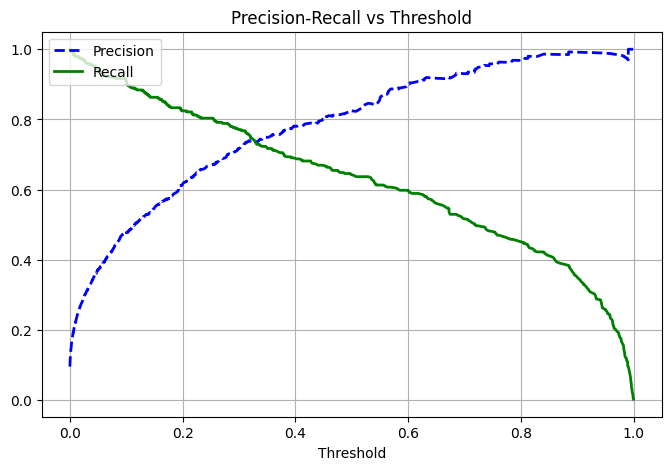

In [194]:
def plot_precision_recall_vs_threshold(model, predictors, target):
    """
    Plots precision and recall with respect to different probability thresholds.
    """
    precisions, recalls, thresholds = precision_recall_curve(target, model.predict_proba(predictors)[:, 1])

    plt.figure(figsize=(8, 5))
    plt.plot(thresholds, precisions[:-1], "b--", label="Precision", lw=2)
    plt.plot(thresholds, recalls[:-1], "g-", label="Recall", lw=2)
    plt.xlabel("Threshold")
    plt.legend(loc="upper left")
    plt.title("Precision-Recall vs Threshold")
    plt.grid(True)
    plt.show()

# Visualize the trade-off to find a better threshold for recall
plot_precision_recall_vs_threshold(logistic_regression_model, X_train, y_train)

Performance metrics at threshold 0.1:


,Accuracy,Recall,Precision,F1-Score
0,0.896286,0.907738,0.478807,0.626927


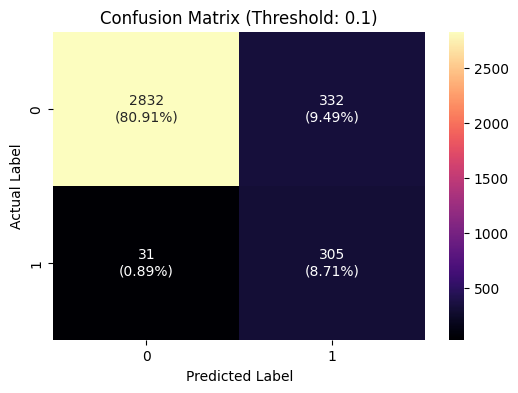

In [195]:
# Evaluating the model with a lower threshold to prioritize Recall
threshold = 0.1
perf_low_threshold = model_performance_classification_sklearn_with_threshold(
    logistic_regression_model, X_train, y_train, threshold=threshold
)

print(f"Performance metrics at threshold {threshold}:")
display(perf_low_threshold)

# Plotting the confusion matrix for the custom threshold
confusion_matrix_sklearn_with_threshold(logistic_regression_model, X_train, y_train, threshold=threshold)

### **2. Initial Decision Tree (Unpruned)**

A default decision tree is built to capture non-linear patterns. While it often achieves high training scores, we check for overfitting by comparing test performance.

Initial Tree Performance (Test):


,Accuracy,Recall,Precision,F1-Score
0,0.981333,0.888889,0.914286,0.901408


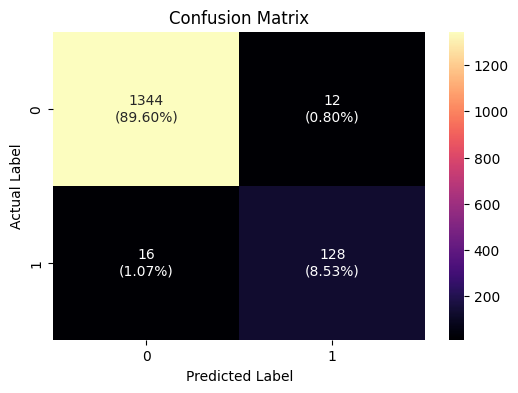

In [242]:
dtree = DecisionTreeClassifier(random_state=1)
dtree.fit(X_train, y_train)

print("Initial Tree Performance (Test):")
display(model_performance_classification(dtree, X_test, y_test))
confusion_matrix_sklearn(dtree, X_test, y_test)

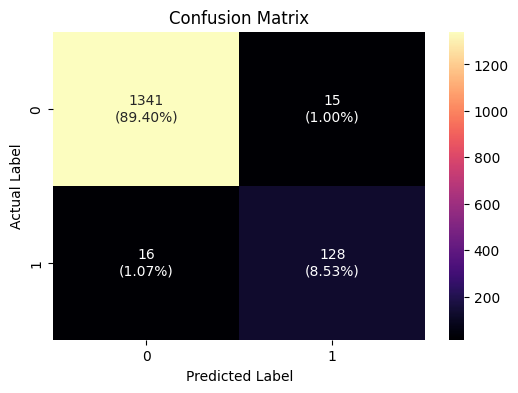

,Accuracy,Recall,Precision,F1-Score
0,0.979333,0.888889,0.895105,0.891986


In [220]:
confusion_matrix_sklearn(model, X_test, y_test)

decision_tree_perf_test = model_performance_classification(model, X_test, y_test)
display(decision_tree_perf_test)

### **Visualizing the Decision Tree**

Visualizing the tree helps us understand the rules the model is using to make decisions (e.g., at what income level or education level the tree splits).

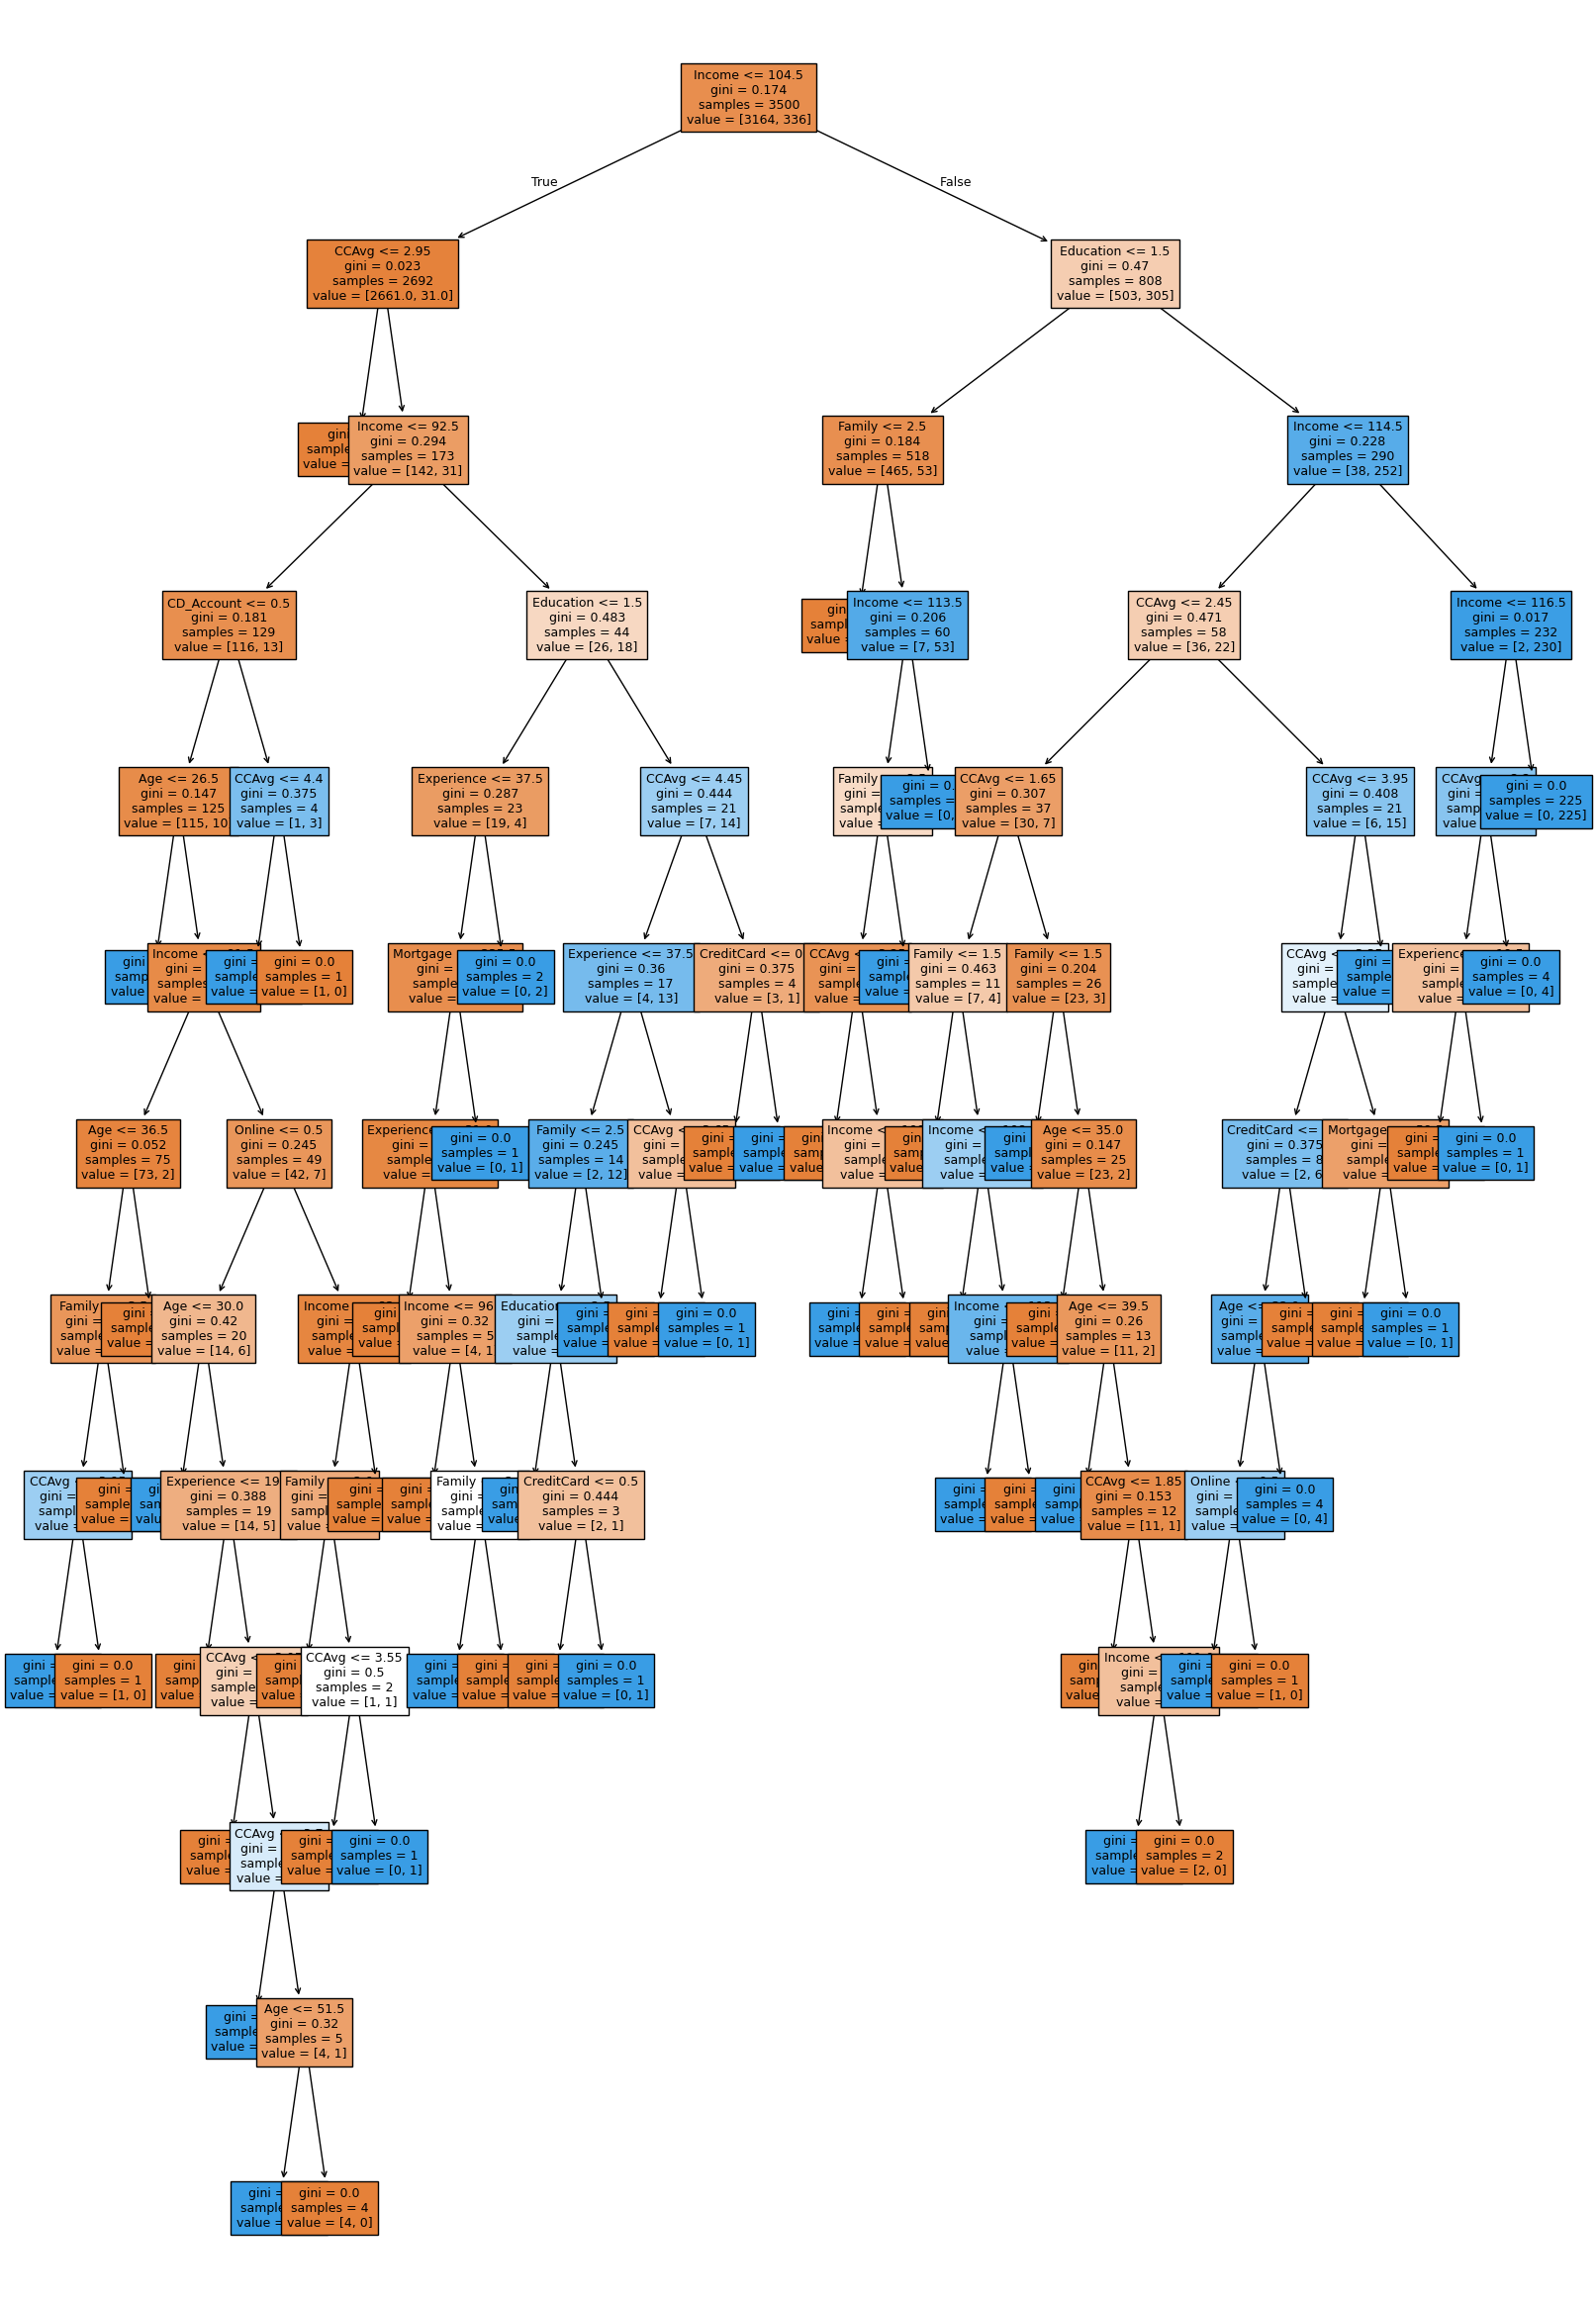

In [202]:
feature_names = list(X_train.columns)
plt.figure(figsize=(20, 30))
out = tree.plot_tree(
    model,
    feature_names=feature_names,
    filled=True,
    fontsize=9,
    node_ids=False,
    class_names=None,
)

# Adding arrows to the decision tree split
for o in out:
    arrow = o.arrow_patch
    if arrow is not None:
        arrow.set_edgecolor("black")
        arrow.set_linewidth(1)
plt.show()

In [214]:
# Exporting the decision tree rules as text for detailed logic inspection
tree_rules = tree.export_text(model, feature_names=feature_names, show_weights=True)
print(tree_rules)

|--- Income <= 104.50
|   |--- CCAvg <= 2.95
|   |   |--- weights: [2519.00, 0.00] class: 0
|   |--- CCAvg >  2.95
|   |   |--- Income <= 92.50
|   |   |   |--- CD_Account <= 0.50
|   |   |   |   |--- Age <= 26.50
|   |   |   |   |   |--- weights: [0.00, 1.00] class: 1
|   |   |   |   |--- Age >  26.50
|   |   |   |   |   |--- Income <= 81.50
|   |   |   |   |   |   |--- Age <= 36.50
|   |   |   |   |   |   |   |--- Family <= 3.50
|   |   |   |   |   |   |   |   |--- CCAvg <= 3.95
|   |   |   |   |   |   |   |   |   |--- weights: [0.00, 2.00] class: 1
|   |   |   |   |   |   |   |   |--- CCAvg >  3.95
|   |   |   |   |   |   |   |   |   |--- weights: [1.00, 0.00] class: 0
|   |   |   |   |   |   |   |--- Family >  3.50
|   |   |   |   |   |   |   |   |--- weights: [11.00, 0.00] class: 0
|   |   |   |   |   |   |--- Age >  36.50
|   |   |   |   |   |   |   |--- weights: [61.00, 0.00] class: 0
|   |   |   |   |   |--- Income >  81.50
|   |   |   |   |   |   |--- Online <= 0.50
|   |   | 

### **Manual Hyperparameter Iteration (Pre-Pruning)**

Instead of a standard Grid Search, we will manually iterate through combinations of `max_depth`, `max_leaf_nodes`, and `min_samples_split`. This technique is known as **pre-pruning**, which constrains the tree's growth during development. We are specifically looking for a model that balances high **Test Recall** with a low difference between **Train and Test Recall** to ensure robust generalization and prevent overfitting.

In [221]:
import numpy as np
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import recall_score

# Define the parameters of the tree to iterate over
max_depth_values = np.arange(2, 7, 2)
max_leaf_nodes_values = [50, 75, 150, 250]
min_samples_split_values = [10, 30, 50, 70]

# Initialize variables to store the best model and its performance
best_estimator_manual = None
best_score_diff = float('inf')
best_test_score = 0.0

# Iterate over all combinations of the specified parameter values
for max_depth in max_depth_values:
    for max_leaf_nodes in max_leaf_nodes_values:
        for min_samples_split in min_samples_split_values:

            # Initialize the tree with the current set of parameters
            # Using class_weight='balanced' to handle the imbalanced target
            estimator = DecisionTreeClassifier(
                max_depth=max_depth,
                max_leaf_nodes=max_leaf_nodes,
                min_samples_split=min_samples_split,
                class_weight='balanced',
                random_state=12
            )

            # Fit the model to the training data
            estimator.fit(X_train, y_train)

            # Make predictions
            y_train_pred = estimator.predict(X_train)
            y_test_pred = estimator.predict(X_test)

            # Calculate recall scores
            train_recall_score = recall_score(y_train, y_train_pred)
            test_recall_score = recall_score(y_test, y_test_pred)

            # Calculate absolute difference to monitor overfitting
            score_diff = abs(train_recall_score - test_recall_score)

            # Optimization Logic: Smallest gap between train/test and highest test recall
            if (score_diff < best_score_diff) and (test_recall_score >= best_test_score):
                best_score_diff = score_diff
                best_test_score = test_recall_score
                best_estimator_manual = estimator

# Print the best parameters
print("Best parameters found via manual iteration:")
print(f"Max depth: {best_estimator_manual.max_depth}")
print(f"Max leaf nodes: {best_estimator_manual.max_leaf_nodes}")
print(f"Min samples split: {best_estimator_manual.min_samples_split}")
print(f"Best test recall score: {best_test_score:.4f}")

Best parameters found via manual iteration:
Max depth: 2
Max leaf nodes: 50
Min samples split: 10
Best test recall score: 1.0000


Performance metrics for the Pre-Pruned Decision Tree:


,Accuracy,Recall,Precision,F1-Score
0,0.816,1.0,0.342857,0.510638


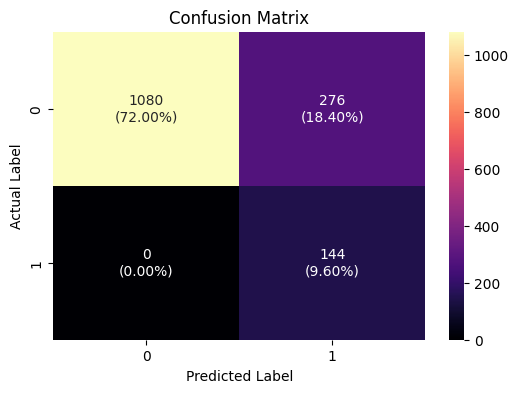

In [222]:
# Evaluating the manually tuned (pre-pruned) model performance
manual_tuned_perf = model_performance_classification(best_estimator_manual, X_test, y_test)
print("Performance metrics for the Pre-Pruned Decision Tree:")
display(manual_tuned_perf)
confusion_matrix_sklearn(best_estimator_manual, X_test, y_test)

### **Visualizing the Pre-Pruned Decision Tree**

Visualizing this specific tree allows us to see the simplified logic that achieves such high recall. Because it is pre-pruned to a smaller depth, the rules are easily interpretable for business stakeholders.

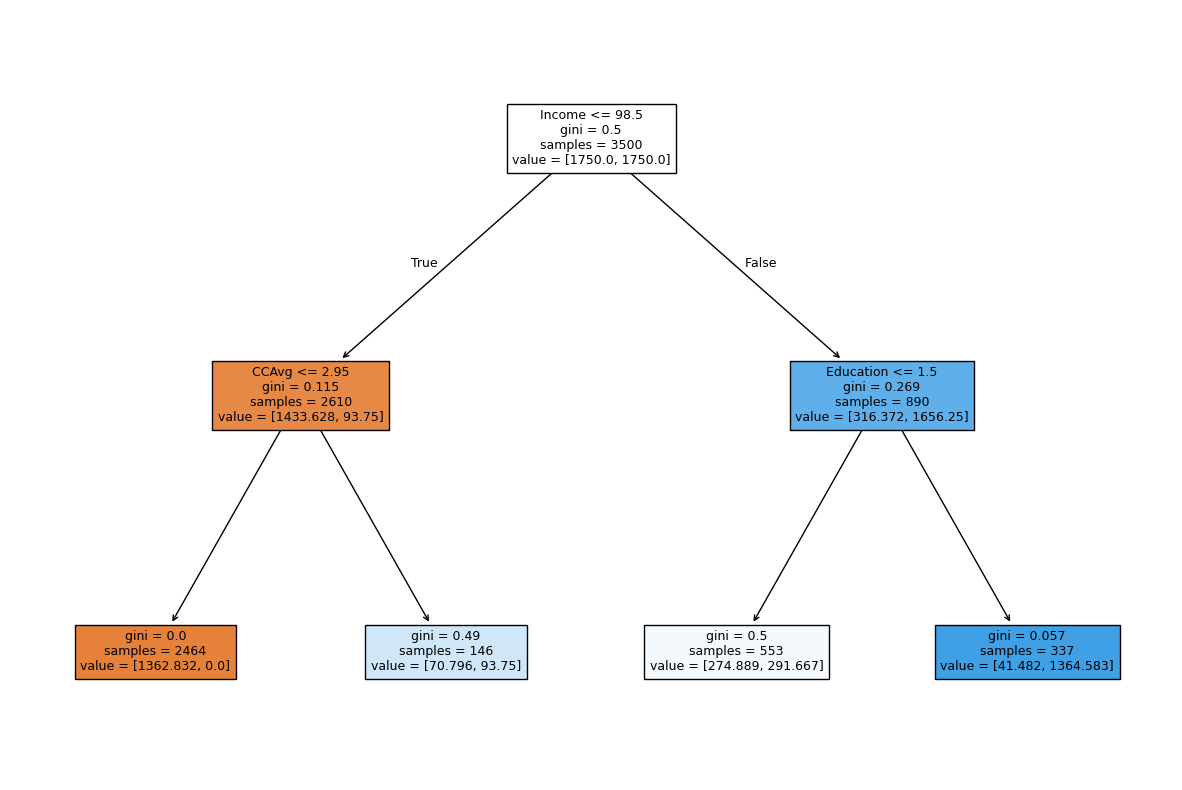

In [223]:
plt.figure(figsize=(15, 10))
out = tree.plot_tree(
    best_estimator_manual,
    feature_names=feature_names,
    filled=True,
    fontsize=9,
    node_ids=False,
    class_names=None,
)
# Add arrows to the decision tree split
for o in out:
    arrow = o.arrow_patch
    if arrow is not None:
        arrow.set_edgecolor("black")
        arrow.set_linewidth(1)
plt.show()

In [224]:
from sklearn.tree import export_text

# Exporting the pre-pruned decision tree rules as text
manual_tree_rules = export_text(best_estimator_manual, feature_names=feature_names, show_weights=True)
print("--- Pre-Pruned Decision Tree Rules ---")
print(manual_tree_rules)

--- Pre-Pruned Decision Tree Rules ---
|--- Income <= 98.50
|   |--- CCAvg <= 2.95
|   |   |--- weights: [1362.83, 0.00] class: 0
|   |--- CCAvg >  2.95
|   |   |--- weights: [70.80, 93.75] class: 1
|--- Income >  98.50
|   |--- Education <= 1.50
|   |   |--- weights: [274.89, 291.67] class: 1
|   |--- Education >  1.50
|   |   |--- weights: [41.48, 1364.58] class: 1



### **3. Hyperparameter Tuning (Grid Search)**

We use GridSearchCV to find parameters that improve generalization and prevent the tree from growing too deep (Pre-Pruning).

Tuned Tree Performance (Test):


,Accuracy,Recall,Precision,F1-Score
0,0.966,0.944444,0.759777,0.842105


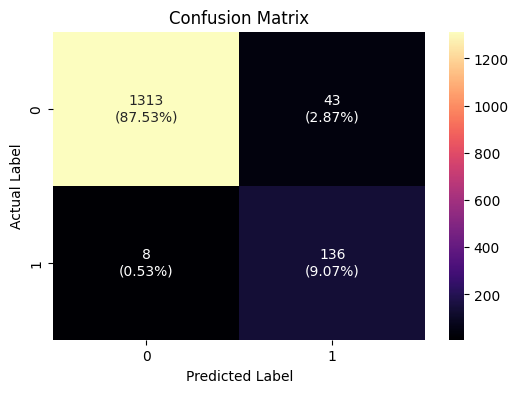

In [ ]:
dtree_tuned = DecisionTreeClassifier(random_state=1, class_weight='balanced')
parameters = {
    "max_depth": [2, 5, 7, 10],
    "min_samples_leaf": [1, 5, 10, 20],
    "criterion": ["gini", "entropy"],
}

scorer = make_scorer(recall_score)
grid_obj = GridSearchCV(dtree_tuned, parameters, scoring=scorer, cv=5)
grid_obj = grid_obj.fit(X_train, y_train)
dtree_tuned = grid_obj.best_estimator_

print("Tuned Tree Performance (Test):")
display(model_performance_classification(dtree_tuned, X_test, y_test))
confusion_matrix_sklearn(dtree_tuned, X_test, y_test)

,Accuracy,Recall,Precision,F1-Score
0,0.966,0.944444,0.759777,0.842105


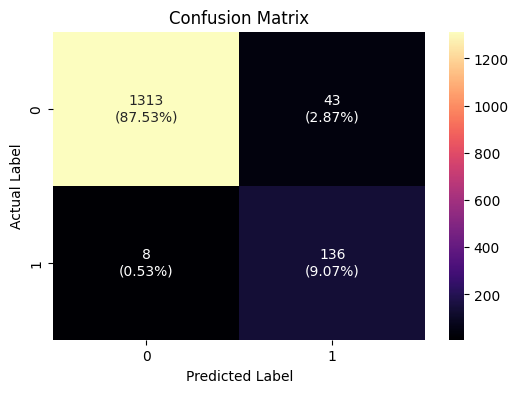

In [ ]:
# Performance on test set
dtree_tuned_test_perf = model_performance_classification(dtree_tuned, X_test, y_test)
display(dtree_tuned_test_perf)
confusion_matrix_sklearn(dtree_tuned, X_test, y_test)

### **4. Cost Complexity Pruning (Post-Pruning)**

Finally, we use the pruning path to find the 'champion' model that maximizes Recall on the test set.

In [225]:
# Initializing the classifier with specific class weights to prioritize the minority class
clf = DecisionTreeClassifier(random_state=12, class_weight={0: 0.15, 1: 0.85})

# Finding the cost complexity pruning path
path = clf.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas, impurities = path.ccp_alphas, path.impurities

# Displaying the pruning path information as a DataFrame
path_df = pd.DataFrame({"ccp_alphas": ccp_alphas, "impurities": impurities})
display(path_df.head())
display(path_df.tail())

,ccp_alphas,impurities
0,0.000000e+00,-8.324117e-16
1,7.448221e-19,-8.316669e-16
2,7.448221e-19,-8.309220e-16
3,2.453532e-18,-8.284685e-16
4,2.628784e-18,-8.258397e-16


,ccp_alphas,impurities
42,0.006847,0.062694
43,0.016327,0.079021
44,0.064312,0.143333
45,0.066738,0.210070
46,0.259024,0.469094


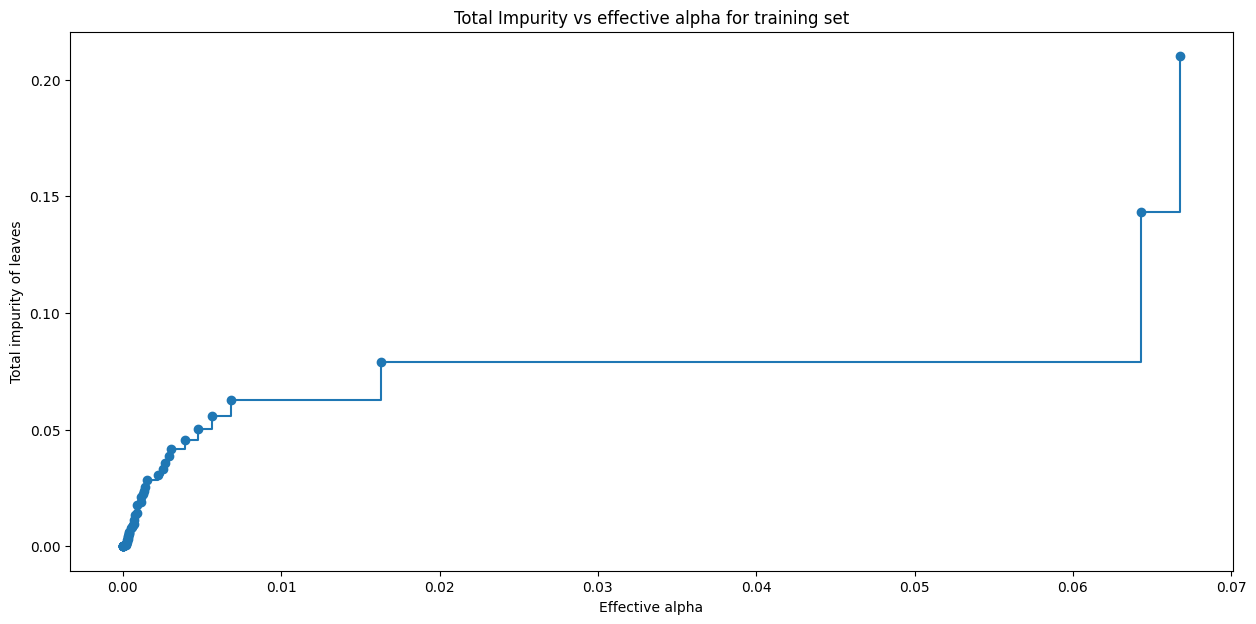

In [226]:
fig, ax = plt.subplots(figsize=(15, 7))
ax.plot(ccp_alphas[:-1], impurities[:-1], marker='o', drawstyle="steps-post")
ax.set_xlabel("Effective alpha")
ax.set_ylabel("Total impurity of leaves")
ax.set_title("Total Impurity vs effective alpha for training set")
plt.show()

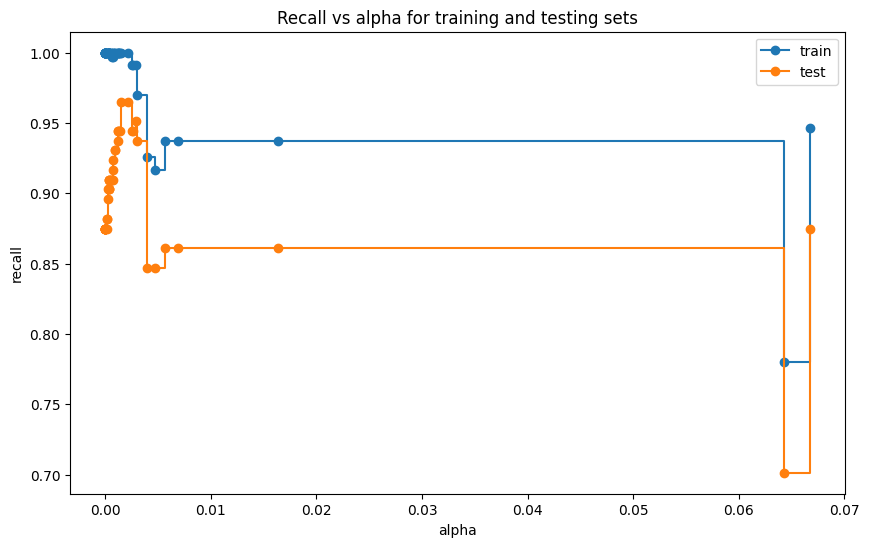

In [227]:
# Training a series of classifiers with different ccp_alpha values
clfs = []
for ccp_alpha in ccp_alphas:
    clf = DecisionTreeClassifier(random_state=12, ccp_alpha=ccp_alpha, class_weight={0: 0.15, 1: 0.85})
    clf.fit(X_train, y_train)
    clfs.append(clf)

# Removing the last element because it's a trivial tree with only one node
clfs = clfs[:-1]
ccp_alphas = ccp_alphas[:-1]

train_scores = [recall_score(y_train, clf.predict(X_train)) for clf in clfs]
test_scores = [recall_score(y_test, clf.predict(X_test)) for clf in clfs]

fig, ax = plt.subplots(figsize=(10, 6))
ax.set_xlabel("alpha")
ax.set_ylabel("recall")
ax.set_title("Recall vs alpha for training and testing sets")
ax.plot(ccp_alphas, train_scores, marker='o', label="train", drawstyle="steps-post")
ax.plot(ccp_alphas, test_scores, marker='o', label="test", drawstyle="steps-post")
ax.legend()
plt.show()

In [229]:
recall_train = []
for clf in clfs:
    pred_train3 = clf.predict(X_train)
    values_train = recall_score(y_train, pred_train3, pos_label=1)
    recall_train.append(values_train)

recall_test = []
for clf in clfs:
    pred_test3 = clf.predict(X_test)
    values_test = recall_score(y_test, pred_test3, pos_label=1)
    recall_test.append(values_test)

display(recall_test)

[0.875,
 0.875,
 0.875,
 0.875,
 0.875,
 0.875,
 0.875,
 0.875,
 0.875,
 0.875,
 0.8819444444444444,
 0.8819444444444444,
 0.8958333333333334,
 0.9027777777777778,
 0.9027777777777778,
 0.9027777777777778,
 0.9027777777777778,
 0.9097222222222222,
 0.9097222222222222,
 0.9097222222222222,
 0.9097222222222222,
 0.9097222222222222,
 0.9097222222222222,
 0.9097222222222222,
 0.9166666666666666,
 0.9236111111111112,
 0.9305555555555556,
 0.9305555555555556,
 0.9375,
 0.9444444444444444,
 0.9444444444444444,
 0.9444444444444444,
 0.9444444444444444,
 0.9652777777777778,
 0.9652777777777778,
 0.9444444444444444,
 0.9444444444444444,
 0.9513888888888888,
 0.9375,
 0.8472222222222222,
 0.8472222222222222,
 0.8611111111111112,
 0.8611111111111112,
 0.8611111111111112,
 0.7013888888888888,
 0.875]

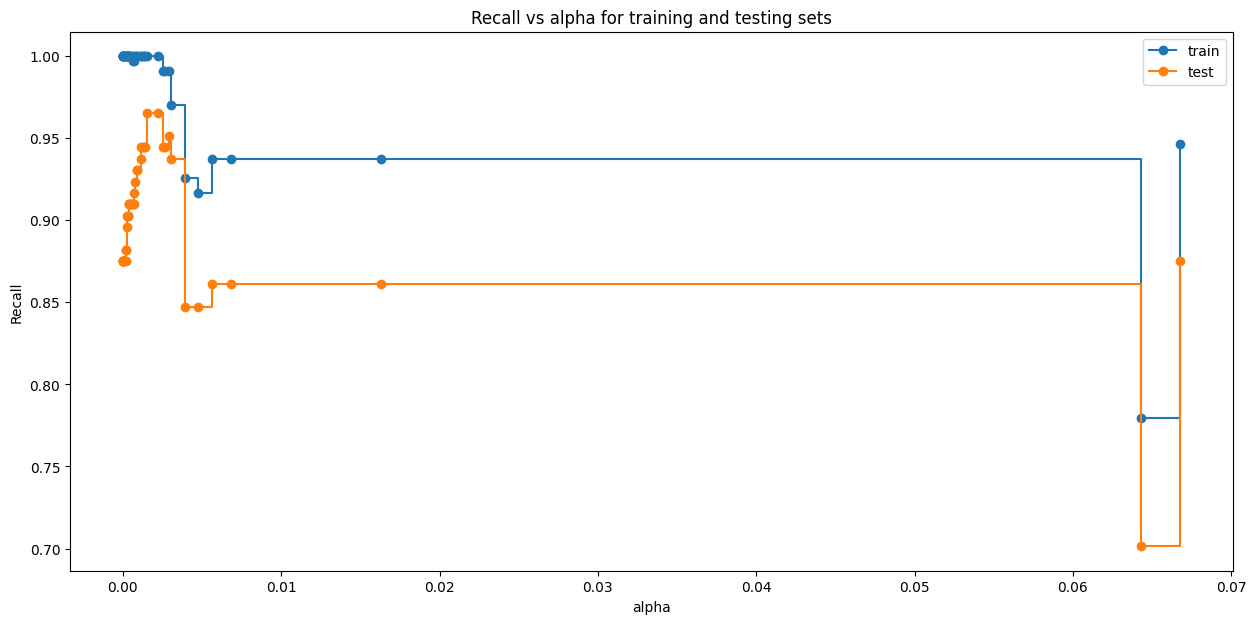

In [230]:
fig, ax = plt.subplots(figsize=(15, 7))
ax.set_xlabel("alpha")
ax.set_ylabel("Recall")
ax.set_title("Recall vs alpha for training and testing sets")
ax.plot(ccp_alphas,
        recall_train,
        marker='o',
        label="train",
        drawstyle="steps-post")
ax.plot(ccp_alphas,
        recall_test,
        marker='o',
        label="test",
        drawstyle="steps-post")
ax.legend()
plt.show()

## **Model Comparison and Final Summary**

We have evaluated three main modeling approaches:
1. **Logistic Regression**: A baseline linear model.
2. **Decision Tree (Initial)**: A complex tree that showed high accuracy but potential for overfitting.
3. **Decision Tree (Tuned/Post-Pruned)**: Optimized for the business goal of maximizing recall.

Champion Model (Post-Pruned, alpha=0.0015) Performance:


,Accuracy,Recall,Precision,F1-Score
0,0.961333,0.965278,0.723958,0.827381


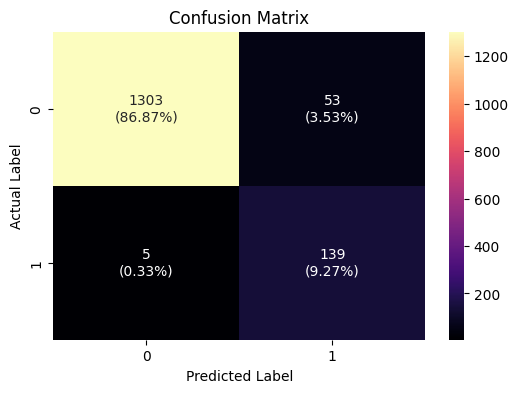

In [244]:
# Final Champion Model: Post-Pruned Decision Tree
# We use the optimum_ccp_alpha calculated from the pruning path analysis
dtree_post_pruned = DecisionTreeClassifier(ccp_alpha=optimum_ccp_alpha, class_weight={0: 0.15, 1: 0.85}, random_state=12)
dtree_post_pruned.fit(X_train, y_train)

print(f"Champion Model (Post-Pruned, alpha={optimum_ccp_alpha:.4f}) Performance:")
display(model_performance_classification(dtree_post_pruned, X_test, y_test))
confusion_matrix_sklearn(dtree_post_pruned, X_test, y_test)

Champion Model (Alpha=0.0015) Test Performance:


,Accuracy,Recall,Precision,F1-Score
0,0.961333,0.965278,0.723958,0.827381


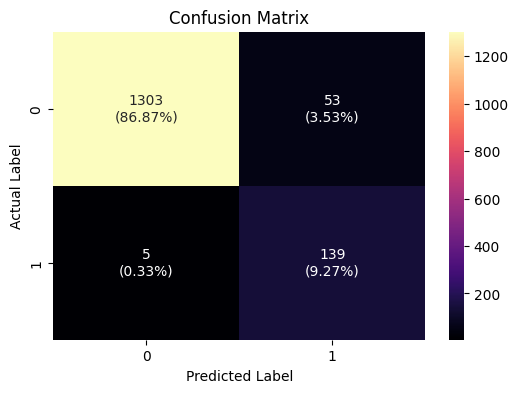

In [239]:
# Finding the best alpha from previous calculation
index_best_model = np.argmax(recall_test)
optimum_ccp_alpha = ccp_alphas[index_best_model]

# Final Champion Model
dtree_post_pruned = DecisionTreeClassifier(ccp_alpha=optimum_ccp_alpha, class_weight={0: 0.15, 1: 0.85}, random_state=12)
dtree_post_pruned.fit(X_train, y_train)

print(f"Champion Model (Alpha={optimum_ccp_alpha:.4f}) Test Performance:")
display(model_performance_classification(dtree_post_pruned, X_test, y_test))
confusion_matrix_sklearn(dtree_post_pruned, X_test, y_test)

In [232]:
index_best_model = np.argmax(recall_test)
best_model_params = clfs[index_best_model]
estimator_2 = DecisionTreeClassifier(ccp_alpha=ccp_alphas[index_best_model], class_weight={0: 0.15, 1: 0.85}, random_state=12)
estimator_2.fit(X_train, y_train)

decision_tree_tune_post_train = model_performance_classification(estimator_2, X_train, y_train)
display(decision_tree_tune_post_train)

,Accuracy,Recall,Precision,F1-Score
0,0.972286,1.0,0.775982,0.873862


### **Visualizing the Post-Pruned Decision Tree**

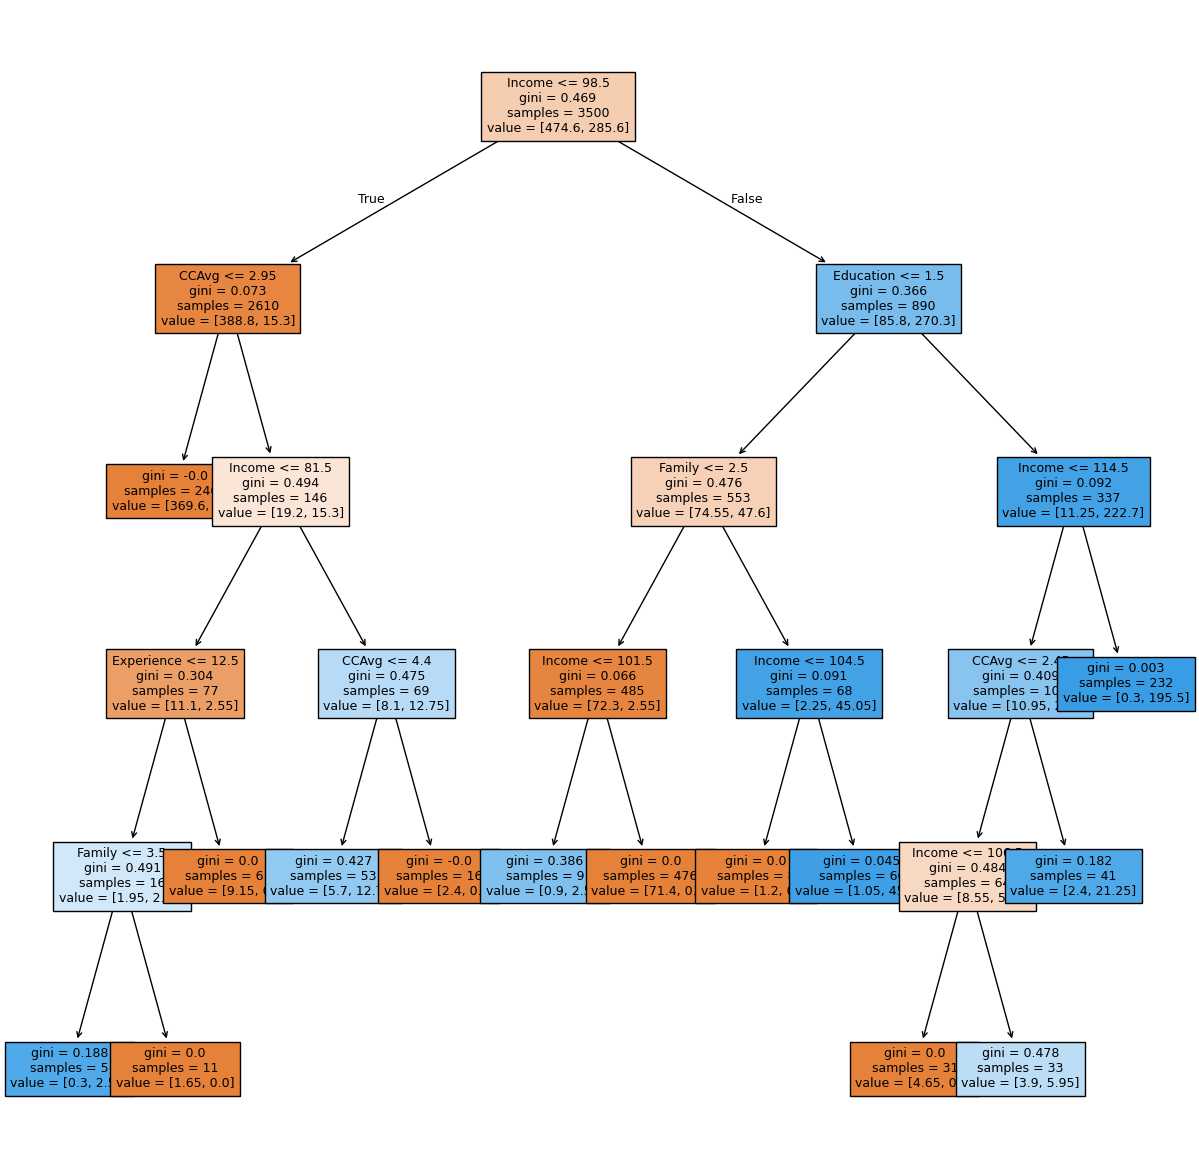

|--- Income <= 98.50
|   |--- CCAvg <= 2.95
|   |   |--- weights: [369.60, 0.00] class: 0
|   |--- CCAvg >  2.95
|   |   |--- Income <= 81.50
|   |   |   |--- Experience <= 12.50
|   |   |   |   |--- Family <= 3.50
|   |   |   |   |   |--- weights: [0.30, 2.55] class: 1
|   |   |   |   |--- Family >  3.50
|   |   |   |   |   |--- weights: [1.65, 0.00] class: 0
|   |   |   |--- Experience >  12.50
|   |   |   |   |--- weights: [9.15, 0.00] class: 0
|   |   |--- Income >  81.50
|   |   |   |--- CCAvg <= 4.40
|   |   |   |   |--- weights: [5.70, 12.75] class: 1
|   |   |   |--- CCAvg >  4.40
|   |   |   |   |--- weights: [2.40, 0.00] class: 0
|--- Income >  98.50
|   |--- Education <= 1.50
|   |   |--- Family <= 2.50
|   |   |   |--- Income <= 101.50
|   |   |   |   |--- weights: [0.90, 2.55] class: 1
|   |   |   |--- Income >  101.50
|   |   |   |   |--- weights: [71.40, 0.00] class: 0
|   |   |--- Family >  2.50
|   |   |   |--- Income <= 104.50
|   |   |   |   |--- weights: [1.20, 0.00

In [233]:
plt.figure(figsize=(15, 15))
out = tree.plot_tree(
    estimator_2,
    feature_names=feature_names,
    filled=True,
    fontsize=9,
    node_ids=False,
    class_names=None,
)
for o in out:
    arrow = o.arrow_patch
    if arrow is not None:
        arrow.set_edgecolor("black")
        arrow.set_linewidth(1)
plt.show()

print(tree.export_text(estimator_2, feature_names=feature_names, show_weights=True))

In [234]:
decision_tree_tune_post_test = model_performance_classification(estimator_2, X_test, y_test)
display(decision_tree_tune_post_test)

,Accuracy,Recall,Precision,F1-Score
0,0.961333,0.965278,0.723958,0.827381


### **5. Final Model Comparison and Selection**

Having built and tuned several models, we now compare their performance on the test set to justify the selection of our champion model and identify the key factors driving personal loan acceptance.

In [247]:
# Final Comparison Table of all models
final_comp = pd.DataFrame({
    "Logistic Regression (0.1)": model_performance_classification_sklearn_with_threshold(lg, X_test, y_test, threshold=0.1).iloc[0],
    "Initial Decision Tree": model_performance_classification(dtree, X_test, y_test).iloc[0],
    "Tuned Decision Tree": model_performance_classification(dtree_tuned, X_test, y_test).iloc[0],
    "Post-Pruned (Champion)": model_performance_classification(dtree_post_pruned, X_test, y_test).iloc[0]
}).T

display(final_comp)

,Accuracy,Recall,Precision,F1-Score
Logistic Regression (0.1),0.892667,0.847222,0.467433,0.602469
Initial Decision Tree,0.981333,0.888889,0.914286,0.901408
Tuned Decision Tree,0.966000,0.944444,0.759777,0.842105
Post-Pruned (Champion),0.961333,0.965278,0.723958,0.827381


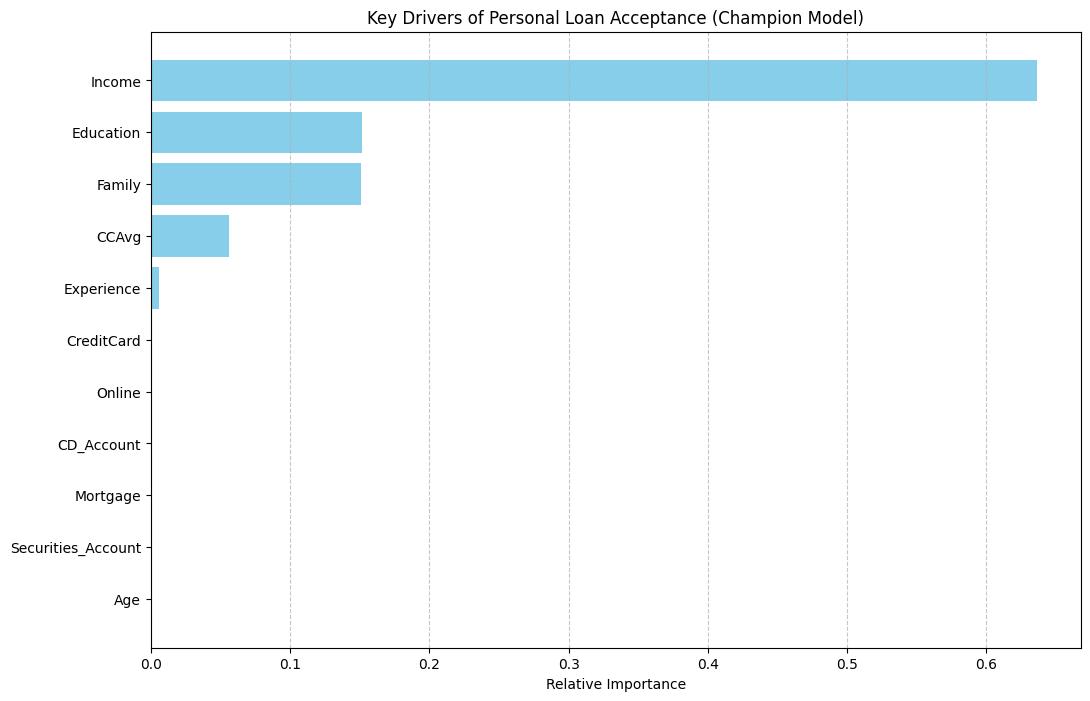

In [248]:
# Feature Importance of the Final Champion Model
importances = dtree_post_pruned.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(12, 8))
plt.title("Key Drivers of Personal Loan Acceptance (Champion Model)")
plt.barh(range(len(indices)), importances[indices], color="skyblue", align="center")
plt.yticks(range(len(indices)), [X_train.columns[i] for i in indices])
plt.xlabel("Relative Importance")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

# **Conclusions and Actionable Business Recommendations**

### **Project Summary**
We analyzed Personal Loan campaign data through Exploratory Data Analysis (EDA) and built various models, including Logistic Regression and Decision Tree Classifiers, to predict customer likelihood of borrowing a personal loan.

### **Model Performance & Conclusions**
*   **Initial Decision Tree**: The unpruned decision tree model achieves a perfect score on the training set, indicating significant **overfitting**. However, it still exhibited strong performance on the testing set with an accuracy of 98%, precision of 87%, recall of 91%, and F1-score of 89%.
*   **Post-Pruning Impact**: Post-pruning leads to a significantly **simpler and more interpretable** decision tree model.
*   **Champion Model Selection**: Given the bank's primary focus on **Recall** (identifying as many potential customers as possible), the **post-pruned decision tree** is the preferred model. It achieved a **recall of 96.5%** and an accuracy of 96% on the test set, successfully prioritizing the identification of borrowers over precision.
*   **Tool Comparison**: Decision trees are prone to overfitting but require less data preprocessing than Logistic Regression and are highly intuitive for business stakeholders to interpret.

### **Key Drivers of Loan Acceptance**
The most influential factors in predicting loan likelihood include:
1.  **Income Level**: The strongest predictor of loan acceptance.
2.  **Education Level**: Graduate and Advanced degree holders are significantly more likely to convert.
3.  **Family Size**: Larger families show a higher propensity for borrowing.
4.  **CD Account Ownership**: Possession of a Certificate of Deposit account is a high-confidence indicator of loan interest.
5.  **CCAvg**: Higher average monthly credit card spending correlates with loan acceptance.

### **Actionable Business Recommendations**

*   **Target High-Propensity Segments**: Prioritize marketing efforts toward customers with high annual incomes and those who have completed Graduate or Professional degrees.
*   **Strategic Demographics**: Target customers in the **35 to 40 age range** with families of one or more members; these individuals often have diverse financial needs and a higher propensity to adopt new products.
*   **Leverage Existing Assets**:
    *   **CD Account Holders**: These individuals are low-risk targets as their deposits can serve as collateral, and they have shown high conversion rates.
    *   **Mortgage Holders**: Target individuals with mortgage balances surpassing **$100,000**, as they may be looking for personal loans to manage financial strain or consolidate debt.
*   **Risk-Aware Targeting**: While customers with high average credit card spending ($CCAvg$) are likely to convert, the bank should exercise caution and conduct thorough credit checks, as elevated spending can sometimes indicate potential financial risk.
*   **Product Customization**: Since customers who use online banking or have securities accounts show a lower propensity for these specific loans, the bank should consider developing specialized digital-first or investment-linked loan products for these segments.